# TP 3: Stabilise, then transform each token

In TP2 one attention head mixed the positions of a sequence. Here I build the two operations that act on each token alone. LayerNorm keeps every token at the same scale, the feed-forward network transforms it, and a residual addition keeps the input.

The diagram follows one token of C = 4 through these steps.

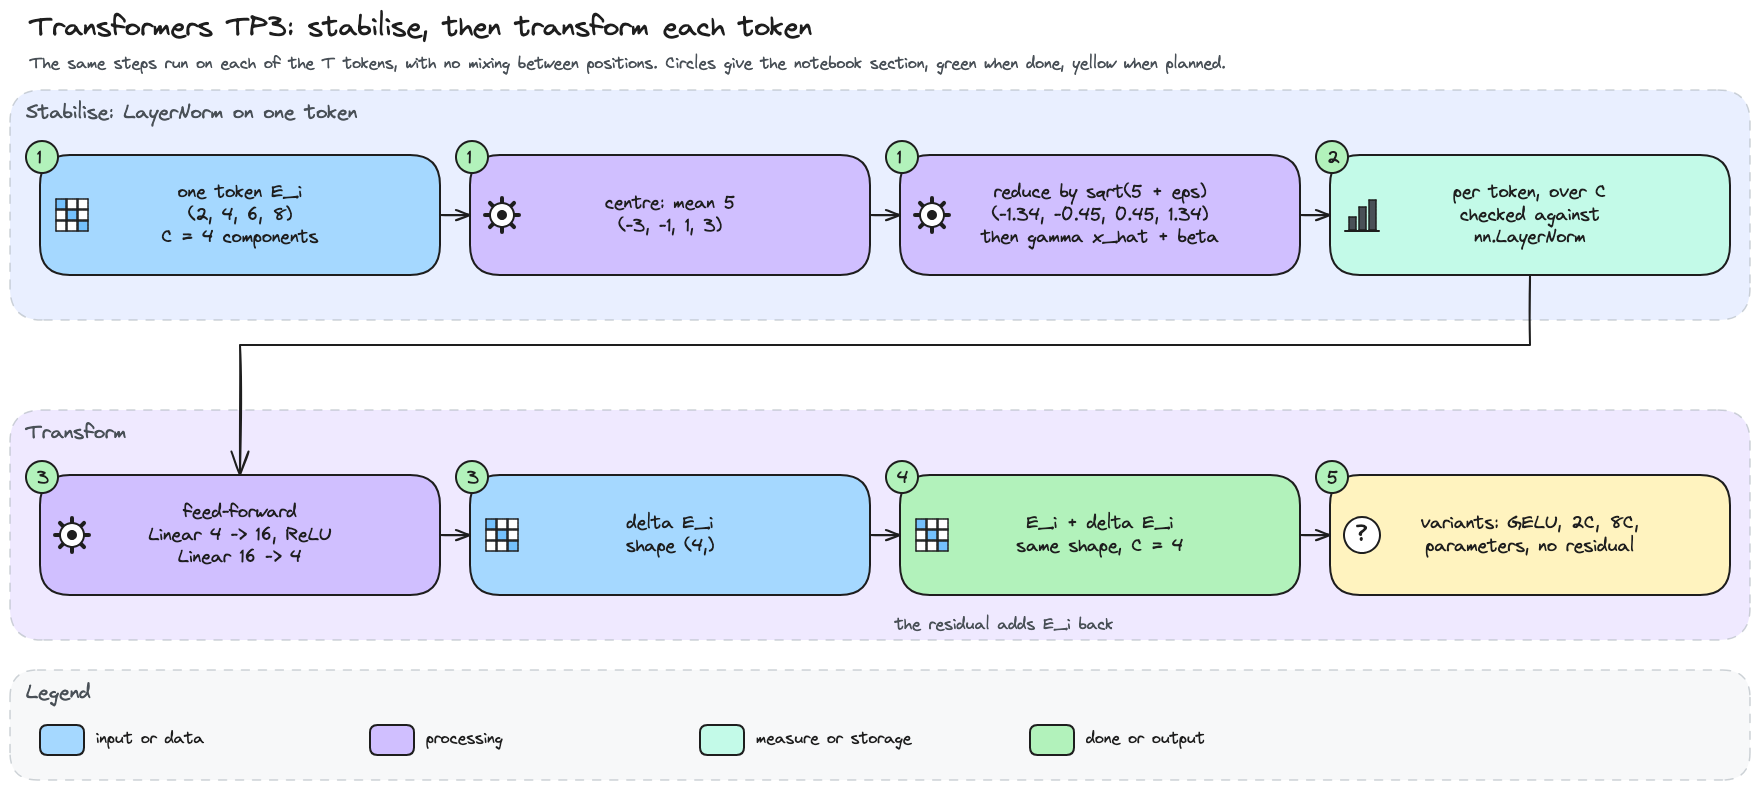

In [1]:
# Workflow diagram: one token through LayerNorm, the feed-forward network and the residual.
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp3_workflow.png', width=900))

## 0. My problem and what I carry over

Section 6 of TP2 showed that the scale of the scores decides whether softmax stays informative. I want the same control over the scale of each token, then a small network that transforms each token on its own. The diagram links each lesson of TP2 to what it changes here.

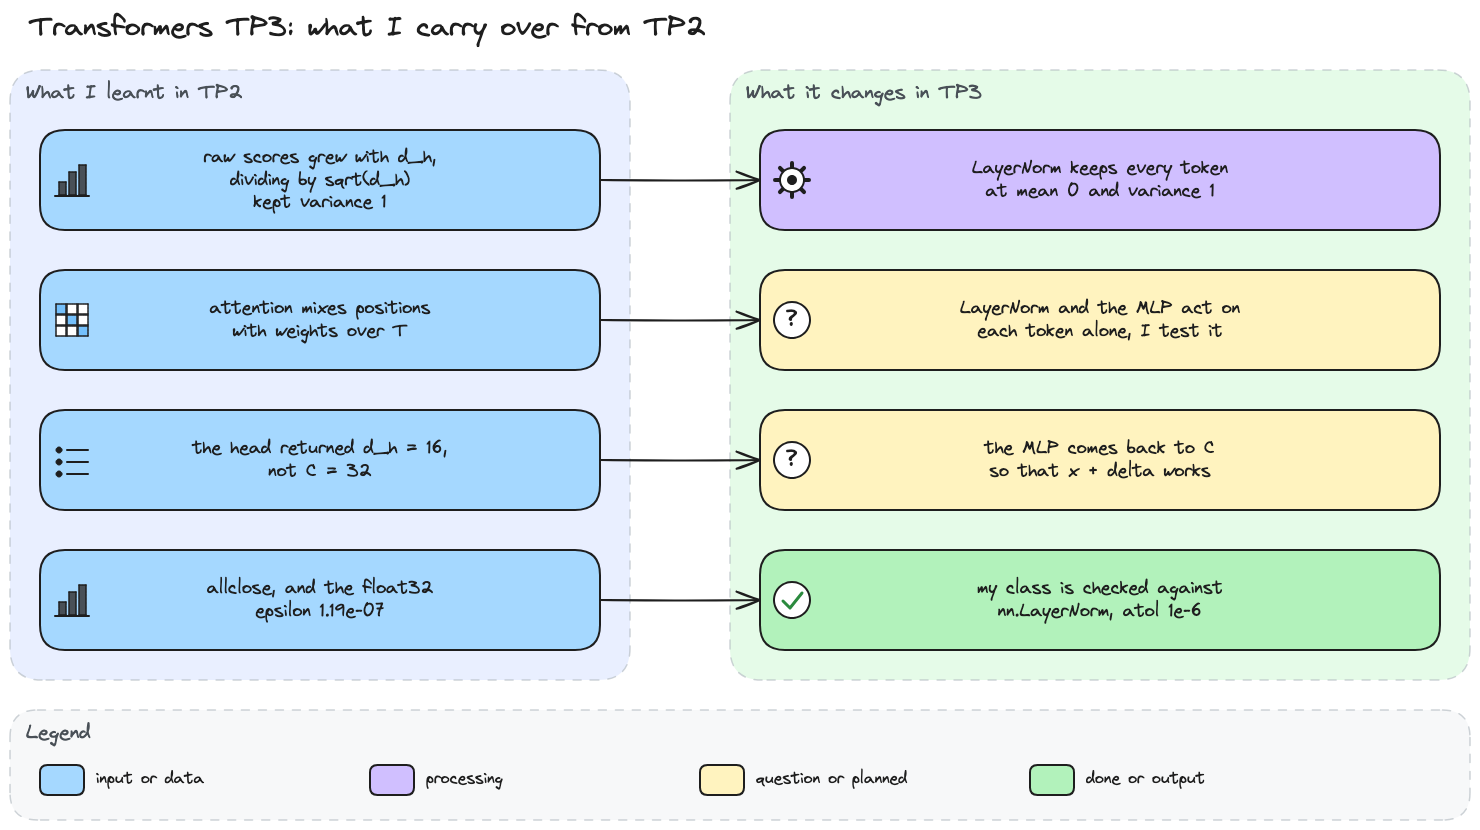

In [2]:
# What I carry over from TP2 (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp3_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - My LayerNorm gives every token a mean of 0 and a standard deviation of 1 over its C components, whatever its scale or shift. Section 1 checks it.
> - On a batch of 32 tokens, the features of one token come out near (0, 1), while one feature across the 32 tokens gets no imposed value. I test both lines in section 2.
> - About half of the ReLU activations are positive, because the first linear layer gives values centred on 0.
> - The feed-forward network acts on each token alone, so changing one token changes only its own output. Section 3 counts the activations and tests this.
> - In the pre-norm block, x_out stays close to x, because delta is small at initialisation. I measure it in section 4.
> - The parameters of the feed-forward network grow linearly with its expansion factor, and removing the residual keeps the shape (B, T, C). Section 5 counts and compares.

### My environment

I use the project's `.venv/bin/python` as kernel, with the same dependencies as in TP1 and TP2.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I keep every tensor on the CPU in this TP, because they are tiny and nothing is trained. I fix seed 42 once, and the handout cells also set their own seeds, so every random draw is the same at every run.

In [3]:
# Environment: versions, hardware and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, and the handout cells set their own seeds too.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Device: CPU, seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Device: CPU, seed: 42


## 1. Code LayerNorm

In TP2 I divided the scores by √d_h to keep their variance at 1. LayerNorm does a similar job on the activations, token by token, with a mean and a variance over the components of each token. I complete the class, then check what it removes and what ε, γ and β do.

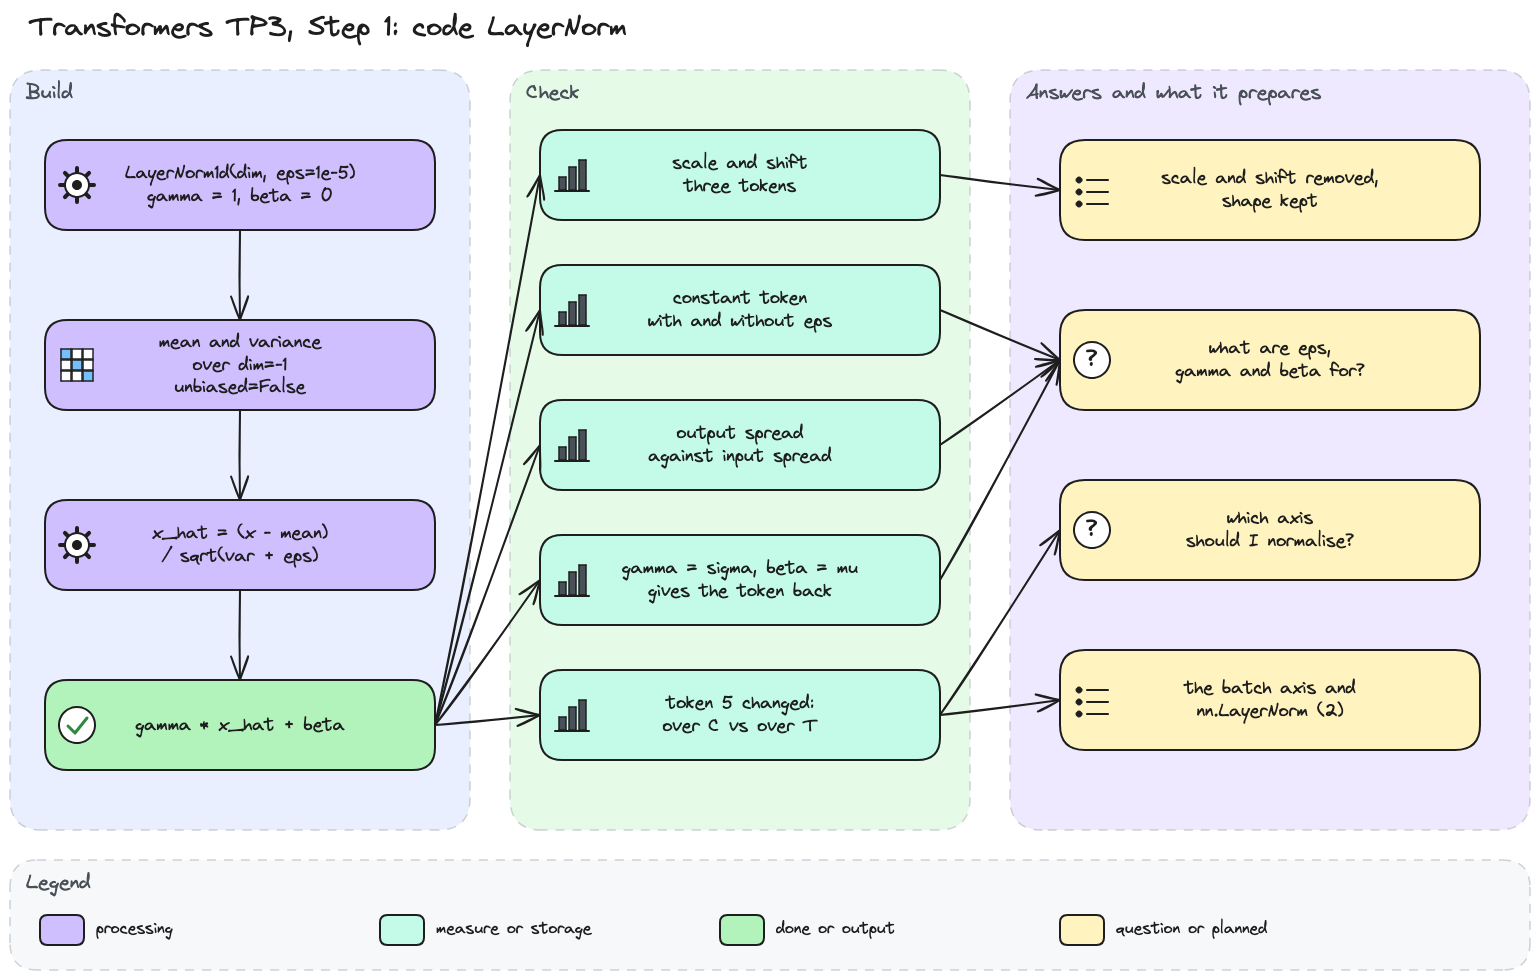

In [4]:
# Step 1 diagram: my LayerNorm, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp3_step1.png', width=900))

In [5]:
# My LayerNorm: mean and variance over the components of each token, then gamma and beta.
class LayerNorm1d:
    """Normalise each vector over its last dimension, then scale by gamma and shift by beta."""

    def __init__(self, dim, eps=1e-5):
        self.eps = eps
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

    def __call__(self, x):
        xmean = x.mean(dim=-1, keepdim=True)
        xvar = x.var(
            dim=-1, keepdim=True, unbiased=False
        )
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        return self.gamma * xhat + self.beta

I fill the two blanks. The statistics go over `dim=-1`, the C components of each token, because I want each token normalised without looking at the others. ε goes inside the square root, next to the variance. I start with tokens of C = 4 that I can check by hand.

Token (2, 4, 6, 8): mean 5, variance 5
[2.0, 4.0, 6.0, 8.0] -> [-1.34, -0.45, 0.45, 1.34]
[20.0, 40.0, 60.0, 80.0] -> [-1.34, -0.45, 0.45, 1.34]
[102.0, 104.0, 106.0, 108.0] -> [-1.34, -0.45, 0.45, 1.34]
Largest absolute mean of the outputs: 3.0e-08, std of each output: [1.0, 1.0, 1.0]


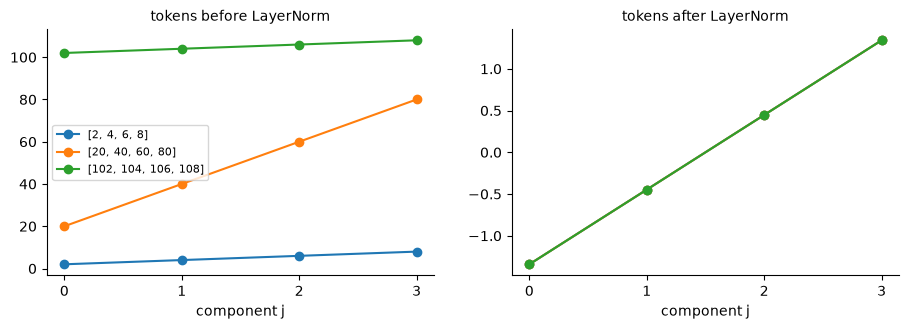

In [6]:
# What does LayerNorm remove? Three tokens of the same shape, at different scales and shifts.
import matplotlib.pyplot as plt

norm = LayerNorm1d(4)
tokens = torch.tensor([[2., 4., 6., 8.], [20., 40., 60., 80.], [102., 104., 106., 108.]])
first = tokens[0]
normed = norm(tokens)

print(f'Token (2, 4, 6, 8): mean {first.mean():.0f}, variance {first.var(unbiased=False):.0f}')
for token, row in zip(tokens.tolist(), normed.tolist()):
    print(f'{token} -> {[round(value, 2) for value in row]}')
print(f'Largest absolute mean of the outputs: {normed.mean(dim=-1).abs().max():.1e}, '
      f'std of each output: {[round(s, 3) for s in normed.std(dim=-1, unbiased=False).tolist()]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for token, row in zip(tokens, normed):
    axes[0].plot(range(4), token, marker='o', label=str(token.int().tolist()))
    axes[1].plot(range(4), row, marker='o')
for ax, title in ((axes[0], 'tokens before LayerNorm'), (axes[1], 'tokens after LayerNorm')):
    ax.set_xticks(range(4))
    ax.set_xlabel('component j')
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

Token (2, 4, 6, 8) has a mean of 5 and a variance of 5, so centring gives (−3, −1, 1, 3) and dividing by √5 gives (−1.34, −0.45, 0.45, 1.34). The token ten times larger and the token shifted by 100 give exactly the same output, and their three lines after LayerNorm lie on top of each other. Every output has a mean within 3.0e-08 of 0 and a std of 1.0, so my first hypothesis holds on these tokens.

LayerNorm keeps only how the components of a token compare with each other. Its scale and its offset are gone. A token whose components are all equal has nothing left to compare, and that is where ε comes in.

In [7]:
# Why eps? A constant token has a variance of 0, normalised with and without eps.
constant = torch.full((1, 4), 5.0)
print(f'Variance of (5, 5, 5, 5): {constant.var(unbiased=False).item()}')
print(f'With eps = 1e-5: {norm(constant).tolist()}')
print(f'With eps = 0: {LayerNorm1d(4, eps=0.0)(constant).tolist()}')

Variance of (5, 5, 5, 5): 0.0
With eps = 1e-5: [[0.0, 0.0, 0.0, 0.0]]
With eps = 0: [[nan, nan, nan, nan]]


The constant token has a variance of 0.0. With ε = 0 the formula divides 0 by 0 and returns NaN everywhere, and every later layer would receive NaN too. With ε = 1e-5 the division is by √ε, and the token becomes all zeros. So ε first keeps the division defined.

I wonder whether ε also changes tokens that are almost constant, so I vary their spread.

spread 0.0001: output std 0.032
spread 0.0003: output std 0.094
spread 0.001: output std 0.302
spread 0.003: output std 0.688
spread 0.01: output std 0.953
spread 0.03: output std 0.994
spread 0.1: output std 1.000
spread 1: output std 1.000
sqrt(eps) = 0.0032


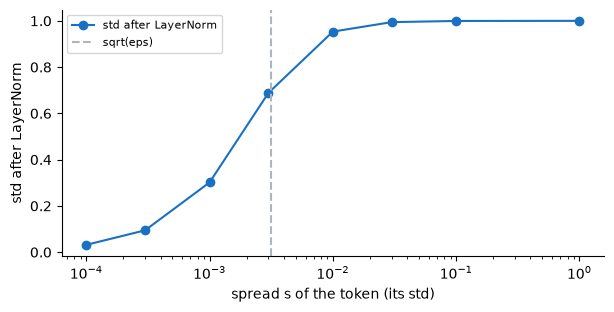

In [8]:
# How much does eps damp a token with a small spread? Output std of (-s, s, -s, s) against s.
import math

SPREADS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1.0]
output_stds = []
for s in SPREADS:
    output_stds.append(norm(torch.tensor([-s, s, -s, s])).std(unbiased=False).item())
    print(f'spread {s:g}: output std {output_stds[-1]:.3f}')
print(f'sqrt(eps) = {math.sqrt(norm.eps):.4f}')

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(SPREADS, output_stds, marker='o', color='#1971c2', label='std after LayerNorm')
ax.axvline(math.sqrt(norm.eps), linestyle='--', color='#adb5bd', label='sqrt(eps)')
ax.set_xscale('log')
ax.set_xlabel('spread s of the token (its std)')
ax.set_ylabel('std after LayerNorm')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Above a spread of 0.03 the output std stays at 0.994 or more, so ε has no visible effect there. Near √ε = 0.0032 it falls to 0.688, and at a spread of 0.0001 only 0.032 is left. The output std follows s / √(s² + ε), which gives 0.003 / √(9e-6 + 1e-5) = 0.688.

So ε keeps a nearly constant token small. Without it, LayerNorm would blow such a token, mostly rounding noise, up to a std of 1.

In [9]:
# What are gamma and beta for? Their starting values, then a choice that undoes the normalisation.
import torch.nn as nn

print(f'gamma: {norm.gamma.tolist()}, beta: {norm.beta.tolist()}')
print(f'Learned values for C = 4: {norm.gamma.numel() + norm.beta.numel()}, '
      f'nn.LayerNorm(4): {sum(p.numel() for p in nn.LayerNorm(4).parameters())}')

undo = LayerNorm1d(4)
undo.gamma = torch.sqrt(first.var(unbiased=False) + undo.eps).expand(4)  # the divisor itself
undo.beta = first.mean().expand(4)
print(f'gamma = sqrt(variance + eps), beta = mean: {undo(first).tolist()}, '
      f'largest gap {(undo(first) - first).abs().max().item():.1e}')

gamma: [1.0, 1.0, 1.0, 1.0], beta: [0.0, 0.0, 0.0, 0.0]
Learned values for C = 4: 8, nn.LayerNorm(4): 8
gamma = sqrt(variance + eps), beta = mean: [2.0, 4.0, 6.0, 8.0], largest gap 0.0e+00


γ starts at 1 and β at 0, so a fresh LayerNorm returns x̂ unchanged. There is one γ and one β per component, 8 learned values for C = 4, the same count as `nn.LayerNorm(4)`. When I set γ to the divisor √(5 + ε) and β to the mean 5, the token (2, 4, 6, 8) comes back with a gap of 0.0. So training can give each component a scale and an offset again, and even undo the normalisation if the next layer needs it.

The last open question of this step is the axis, so I try the other one.

over C, the components: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 2.49, 0.0, 0.0]
over T, the positions: largest change per row [0.85, 0.53, 1.01, 0.68, 0.66, 2.17, 0.87, 0.61]


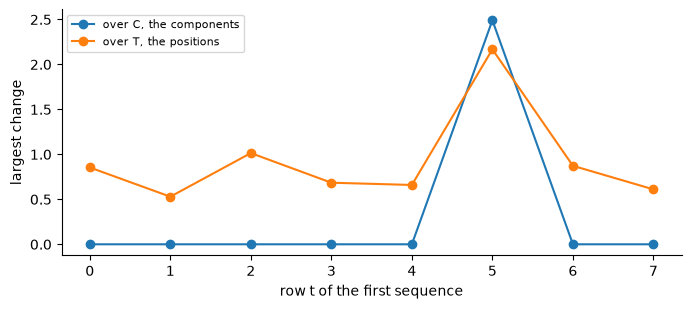

In [10]:
# Which axis? Token 5 of the first sequence replaced, then normalised over C and over T.
torch.manual_seed(1337)
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
changed = x.clone()
changed[0, 5] = torch.randn(C)

norm_c, norm_t = LayerNorm1d(C), LayerNorm1d(T)
versions = {'over C, the components': norm_c,
            # my class on the transposed tensor takes its statistics over the T positions
            'over T, the positions': lambda x: norm_t(x.transpose(1, 2)).transpose(1, 2)}
moves = {}
for name, normalise in versions.items():
    moves[name] = (normalise(changed) - normalise(x))[0].abs().max(dim=-1).values
    print(f'{name}: largest change per row {[round(v, 2) for v in moves[name].tolist()]}')

fig, ax = plt.subplots(figsize=(8, 3.2))
for name, move in moves.items():
    ax.plot(range(T), move, marker='o', label=name)
ax.set_xlabel('row t of the first sequence')
ax.set_ylabel('largest change')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

I change only token 5 of the first sequence. Over C, only row 5 moves, by 2.49, and the other seven rows keep exactly their values. Over T, every row moves, from 0.53 to 1.01 outside row 5, and rows 0 to 4 change although they come before token 5.

Statistics over the positions would let a token see the future through the mean and the variance, which breaks the invariant I kept through TP2. So I normalise over the C components of each token, which keeps every token independent of the others.

> *My conclusion:*
>
> My completed `LayerNorm1d` takes the mean and the biased variance over the last dimension of each token. It removes the scale and the offset, so (2, 4, 6, 8), (20, 40, 60, 80) and (102, 104, 106, 108) all become (−1.34, −0.45, 0.45, 1.34). My hypothesis of a mean of 0 and a std of 1 per token holds.
>
> ε avoids a division by 0 and damps tokens whose spread is below √ε = 0.0032. γ and β then give each component a learned scale and offset. Section 2 looks at the batch axis and checks my class against `nn.LayerNorm`.
>
> My answers to the two questions of this step:
>
> 1. I normalise over the C components of each token, with `dim=-1`. Over the T positions, changing token 5 moved rows 0 to 4, so the past would see the future.
> 2. ε keeps the division defined, since a constant token gives NaN without it. γ and β, one of each per component and starting at 1 and 0, let training rescale and shift the normalised token, up to undoing the normalisation.

## 2. Choose the normalisation axis

Section 1 chose the components of each token as the axis. Here I take a batch of 32 tokens of 100 features and ask what my LayerNorm fixes on each token and what it leaves free on each feature. The diagram shows the handout cell and my checks around it.

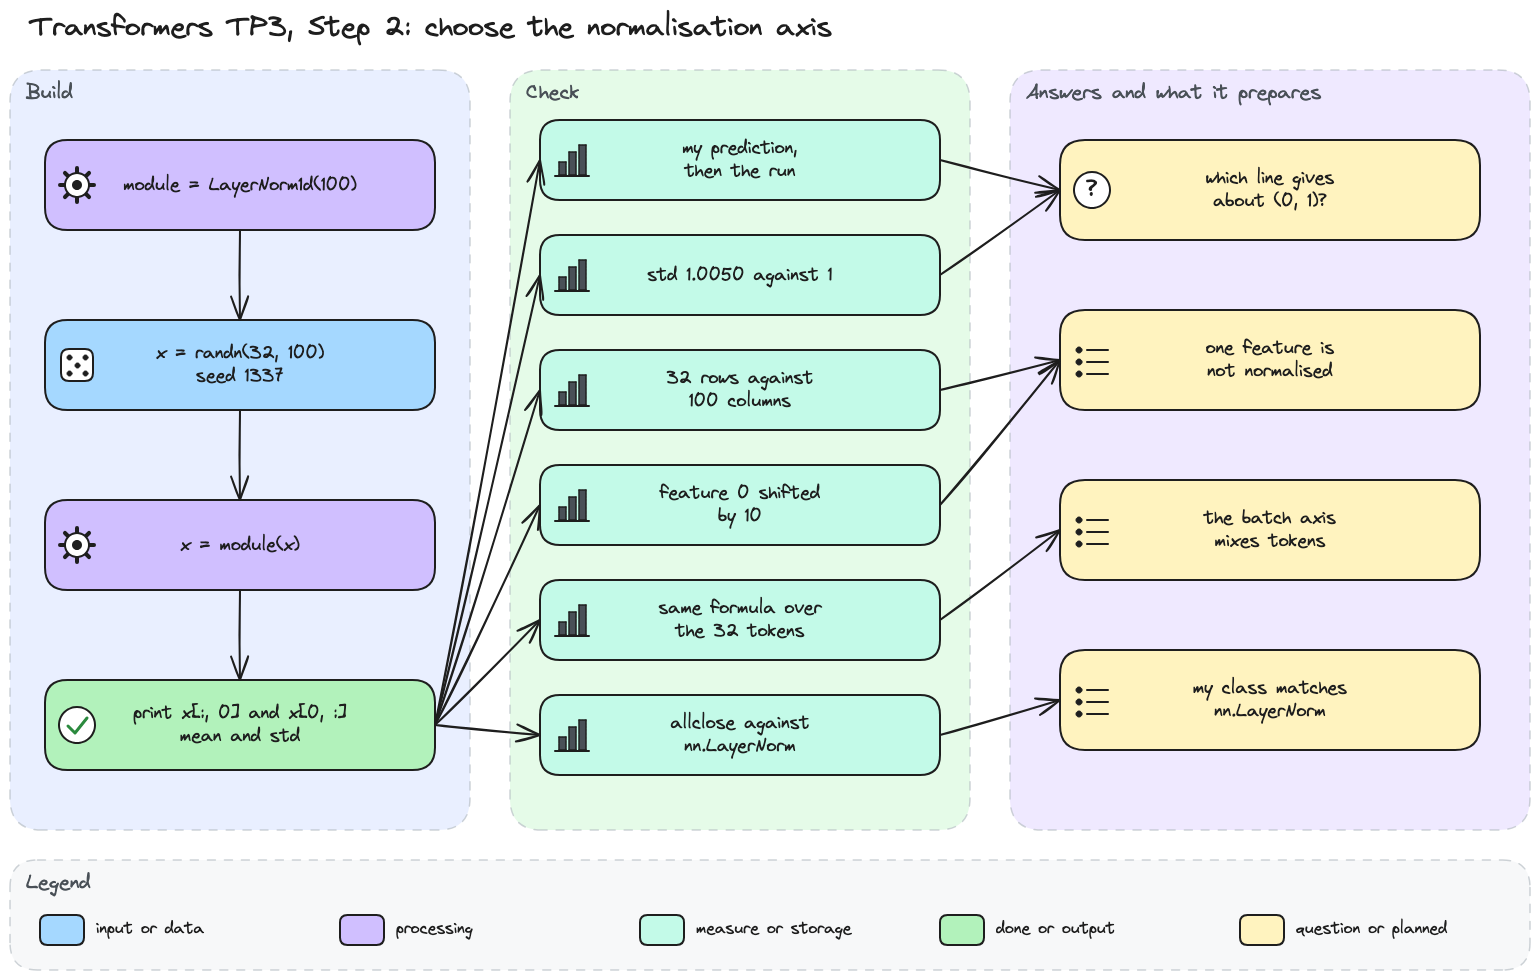

In [11]:
# Step 2 diagram: the handout cell, and the checks behind my answer.
display(Image(filename='diagrams/transformers/tp3_step2.png', width=900))

Before running the handout cell, I write my prediction. `x[0, :]` holds the 100 features of token 0, which my class normalises together, so it should give about (0, 1). `x[:, 0]` holds feature 0 across the 32 tokens, and no statistic of my class is taken over it, so I expect no fixed value.

In [12]:
# Which line gives about (0, 1)? The handout cell, run after writing my prediction.
torch.manual_seed(1337)
module = LayerNorm1d(100)

x = torch.randn(32, 100)
x = module(x)

print(x[:, 0].mean(), x[:, 0].std())
print(x[0, :].mean(), x[0, :].std())

tensor(0.1476) tensor(0.8847)
tensor(-2.3842e-09) tensor(1.0050)


My prediction holds. `x[0, :]` gives a mean of −2.4e-09 and a std of 1.0050, so token 0 sits at (0, 1) up to rounding. `x[:, 0]` gives 0.1476 and 0.8847, values that nothing in my class fixed.

A std of 1.0050 surprises me after a normalisation, so I want to explain it first.

In [13]:
# Why 1.0050 and not 1? The same std with the division by 100 that my LayerNorm uses.
print(f'x[0, :].std(unbiased=False): {x[0, :].std(unbiased=False):.4f}')
print(f'sqrt(100 / 99) = {math.sqrt(100 / 99):.4f}')

x[0, :].std(unbiased=False): 1.0000
sqrt(100 / 99) = 1.0050


With `unbiased=False`, token 0 has a std of exactly 1.0000. The handout calls `.std()`, which divides by 99 instead of 100, so it shows √(100/99) = 1.0050. My class divides by 100, as I chose in section 1, and I check later that `nn.LayerNorm` does the same.

One token and one feature are only two cases, so I look at all 32 tokens and all 100 features.

32 tokens, x[i, :]: means from -0.00 to 0.00, stds from 1.000 to 1.000
100 features, x[:, j]: means from -0.59 to 0.42, stds from 0.742 to 1.399


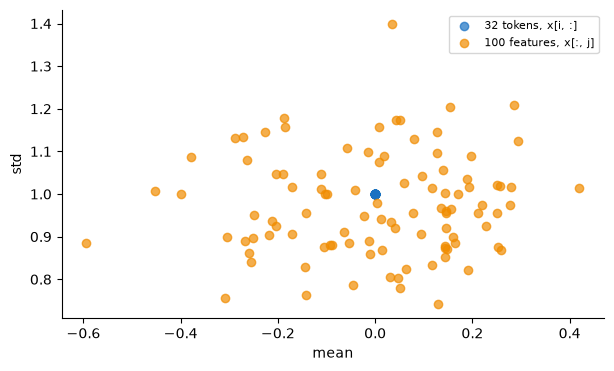

In [14]:
# What is fixed and what is free? Mean and std of the 32 tokens (rows) and the 100 features.
stats = {'32 tokens, x[i, :]': (x.mean(dim=1), x.std(dim=1, unbiased=False)),
         '100 features, x[:, j]': (x.mean(dim=0), x.std(dim=0, unbiased=False))}
for name, (means, stds) in stats.items():
    print(f'{name}: means from {means.min():.2f} to {means.max():.2f}, '
          f'stds from {stds.min():.3f} to {stds.max():.3f}')

fig, ax = plt.subplots(figsize=(7, 4))
for (name, (means, stds)), color in zip(stats.items(), ('#1971c2', '#f08c00')):
    ax.scatter(means, stds, color=color, alpha=0.7, label=name)
ax.set_xlabel('mean')
ax.set_ylabel('std')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Every one of the 32 tokens has a mean of 0.00 and a std of 1.000, and they all sit on a single point of the chart. The 100 features spread out, with means from −0.59 to 0.42 and stds from 0.742 to 1.399. The features stay roughly near (0, 1) only because the input came from `randn`.

I want to see what happens to a feature that is far from 0 in every token.

Same input as the handout cell: True
Feature 0: mean 0.15, std 0.87 without the shift, mean 7.08, std 0.44 with it
Feature 1: mean -0.59, std 0.89 without the shift, mean -0.49, std 0.64 with it
Tokens: largest absolute mean 2.9e-08, stds from 1.000 to 1.000


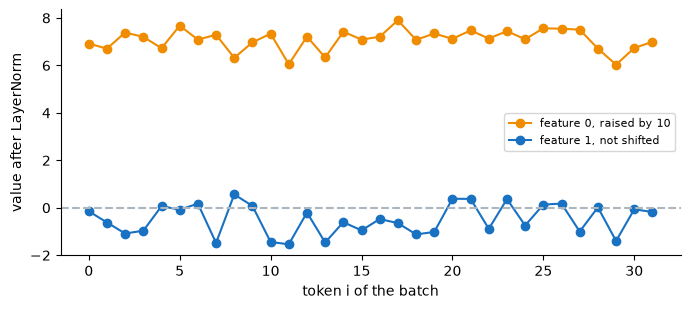

In [15]:
# Can a feature escape the normalisation? Feature 0 raised by 10 in every token, then LayerNorm.
torch.manual_seed(1337)
raw = torch.randn(32, 100)  # the handout input, before normalisation
print(f'Same input as the handout cell: {torch.equal(module(raw), x)}')

shifted = raw.clone()
shifted[:, 0] += 10
out = module(shifted)
for j in (0, 1):
    print(f'Feature {j}: mean {x[:, j].mean():.2f}, std {x[:, j].std(unbiased=False):.2f} '
          f'without the shift, mean {out[:, j].mean():.2f}, '
          f'std {out[:, j].std(unbiased=False):.2f} with it')
print(f'Tokens: largest absolute mean {out.mean(dim=1).abs().max():.1e}, stds from '
      f'{out.std(dim=1, unbiased=False).min():.3f} to {out.std(dim=1, unbiased=False).max():.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(32), out[:, 0], marker='o', color='#f08c00', label='feature 0, raised by 10')
ax.plot(range(32), out[:, 1], marker='o', color='#1971c2', label='feature 1, not shifted')
ax.axhline(0, linestyle='--', color='#adb5bd')
ax.set_xlabel('token i of the batch')
ax.set_ylabel('value after LayerNorm')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Raising feature 0 by 10 in every token moves its normalised mean from 0.15 to 7.08, and its std falls from 0.87 to 0.44. LayerNorm leaves this feature large in every token, so nothing is imposed along the batch.

Feature 1, which I did not touch, also moves, from a mean of −0.59 to −0.49 and from a std of 0.89 to 0.64. The shift raised the mean of every token by 10/100 = 0.1 and widened its spread, so every other feature of a token is rescaled too. The tokens themselves stay at a mean within 2.9e-08 of 0 and a std of 1.000.

over the features, LayerNorm: token 0 moves by 0.00, tokens other than 5 by up to 0.00
over the 32 tokens of the batch: token 0 moves by 0.27, tokens other than 5 by up to 0.43
One token alone, over the batch: largest value 0.0
One token alone, LayerNorm: same output as in the batch True


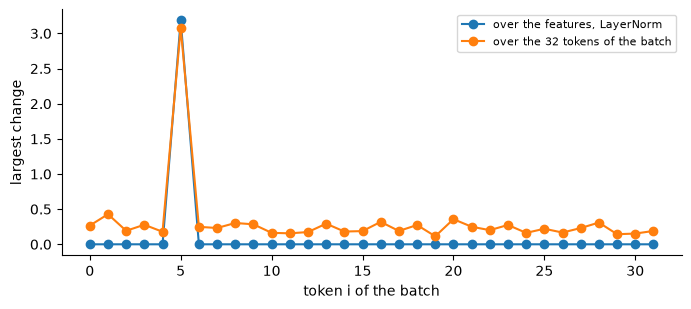

In [16]:
# What if the statistics went over the batch? Token 5 replaced, then both axes on the 32 tokens.
changed = raw.clone()
changed[5] = torch.randn(100)
norm_batch = LayerNorm1d(32)
batch_versions = {'over the features, LayerNorm': module,
                  # my class on the transposed tensor takes its statistics over the 32 tokens
                  'over the 32 tokens of the batch': lambda x: norm_batch(x.T).T}
moves = {}
for name, normalise in batch_versions.items():
    moves[name] = (normalise(changed) - normalise(raw)).abs().max(dim=1).values
    others = torch.cat([moves[name][:5], moves[name][6:]])
    print(f'{name}: token 0 moves by {moves[name][0]:.2f}, '
          f'tokens other than 5 by up to {others.max():.2f}')

alone = raw[:1]
print(f'One token alone, over the batch: largest value {LayerNorm1d(1)(alone.T).T.abs().max():.1f}')
print(f'One token alone, LayerNorm: same output as in the batch '
      f'{torch.allclose(module(alone), module(raw)[:1])}')

fig, ax = plt.subplots(figsize=(8, 3.2))
for name, move in moves.items():
    ax.plot(range(32), move, marker='o', label=name)
ax.set_xlabel('token i of the batch')
ax.set_ylabel('largest change')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

With LayerNorm, replacing token 5 changes no other token, with 0.00 everywhere outside token 5. With the same formula over the 32 tokens, token 0 moves by 0.27 and the other tokens by up to 0.43. Each of them now depends on the mean and the variance of the whole batch. A token alone in its batch collapses to 0.0 on that axis, while LayerNorm gives it the same output as inside the batch.

A batch holds unrelated sequences, so the output of one sequence should not depend on the others. The feature axis gives that, and it still works when I generate a single sequence, as in TP1 transformers.

In [17]:
# Does my class match nn.LayerNorm? The handout check, then the largest gap on three inputs.
print(torch.allclose(module(x), nn.LayerNorm(100)(x), atol=1e-6))

reference = nn.LayerNorm(100)
for name, inputs in (('handout x, already normalised', x), ('raw input', raw),
                     ('raw * 50 + 7', raw * 50 + 7)):
    print(f'{name}: largest gap {(module(inputs) - reference(inputs)).abs().max():.1e}')
print(f'float32 epsilon: {torch.finfo(torch.float32).eps:.2e}')

True
handout x, already normalised: largest gap 4.8e-07
raw input: largest gap 4.8e-07
raw * 50 + 7: largest gap 4.8e-07
float32 epsilon: 1.19e-07


The handout check prints True. The largest gap is 4.8e-07 on the handout `x`, on the raw input and on raw × 50 + 7, about four times the float32 epsilon of 1.19e-07. That is rounding, well under the tolerance of 1e-6. The handout `x` was already normalised, so I am glad the check also holds on raw inputs at a larger scale.

My class starts with γ = 1 and β = 0, which hides any mistake in them, so I test random values next.

In [18]:
# Do gamma, beta and the variance match too? Random gamma and beta in both, then Bessel's variance.
torch.manual_seed(RANDOM_STATE)
with torch.no_grad():
    reference.weight.normal_()
    reference.bias.normal_()
mine = LayerNorm1d(100)
mine.gamma, mine.beta = reference.weight.detach().clone(), reference.bias.detach().clone()
print(f'Random gamma and beta in both: largest gap {(mine(raw) - reference(raw)).abs().max():.1e}, '
      f'allclose {torch.allclose(mine(raw), reference(raw), atol=1e-6)}, '
      f'largest |gamma| {mine.gamma.abs().max():.2f}')

unbiased = (raw - raw.mean(-1, keepdim=True)) / torch.sqrt(raw.var(-1, keepdim=True) + mine.eps)
print(f'Variance divided by 99 instead of 100: largest gap '
      f'{(unbiased - nn.LayerNorm(100)(raw)).abs().max():.3f}')

Random gamma and beta in both: largest gap 1.4e-06, allclose True, largest |gamma| 2.22
Variance divided by 99 instead of 100: largest gap 0.017


With random γ and β copied into both versions, the largest gap grows to 1.4e-06, since a γ of up to 2.22 multiplies the rounding error. `allclose` still returns True, because it also allows a gap relative to the size of the values. With the variance divided by 99, the gap jumps to 0.017, far above any rounding. So `nn.LayerNorm` uses the biased variance, like my class with `unbiased=False`.

> *My conclusion:*
>
> LayerNorm fixes each token at mean 0 and std 1 over its features and leaves every feature free across the batch. All 32 tokens reach (0, 1), while the features keep means from −0.59 to 0.42, and a feature raised by 10 stays near 7.08. My hypothesis on the two lines of the handout holds.
>
> Statistics over the batch would make each token depend on the others, and a token alone would collapse to 0. My class matches `nn.LayerNorm` within 4.8e-07 with the same biased variance, so section 3 can build on it.
>
> My answer to the question of this step:
>
> - I predicted `x[0, :]`, the 100 features of token 0. It gives a mean of −2.4e-09 and a std of 1.0050, or 1.0000 with the division by 100, while `x[:, 0]` gives 0.1476 and 0.8847.

## 3. Build the feed-forward network

Attention moved information between the tokens. This network should work on each token alone, widening it to 4C, applying a ReLU and coming back to C. I complete the class, then ask how many hidden neurons fire and why the output returns to C.

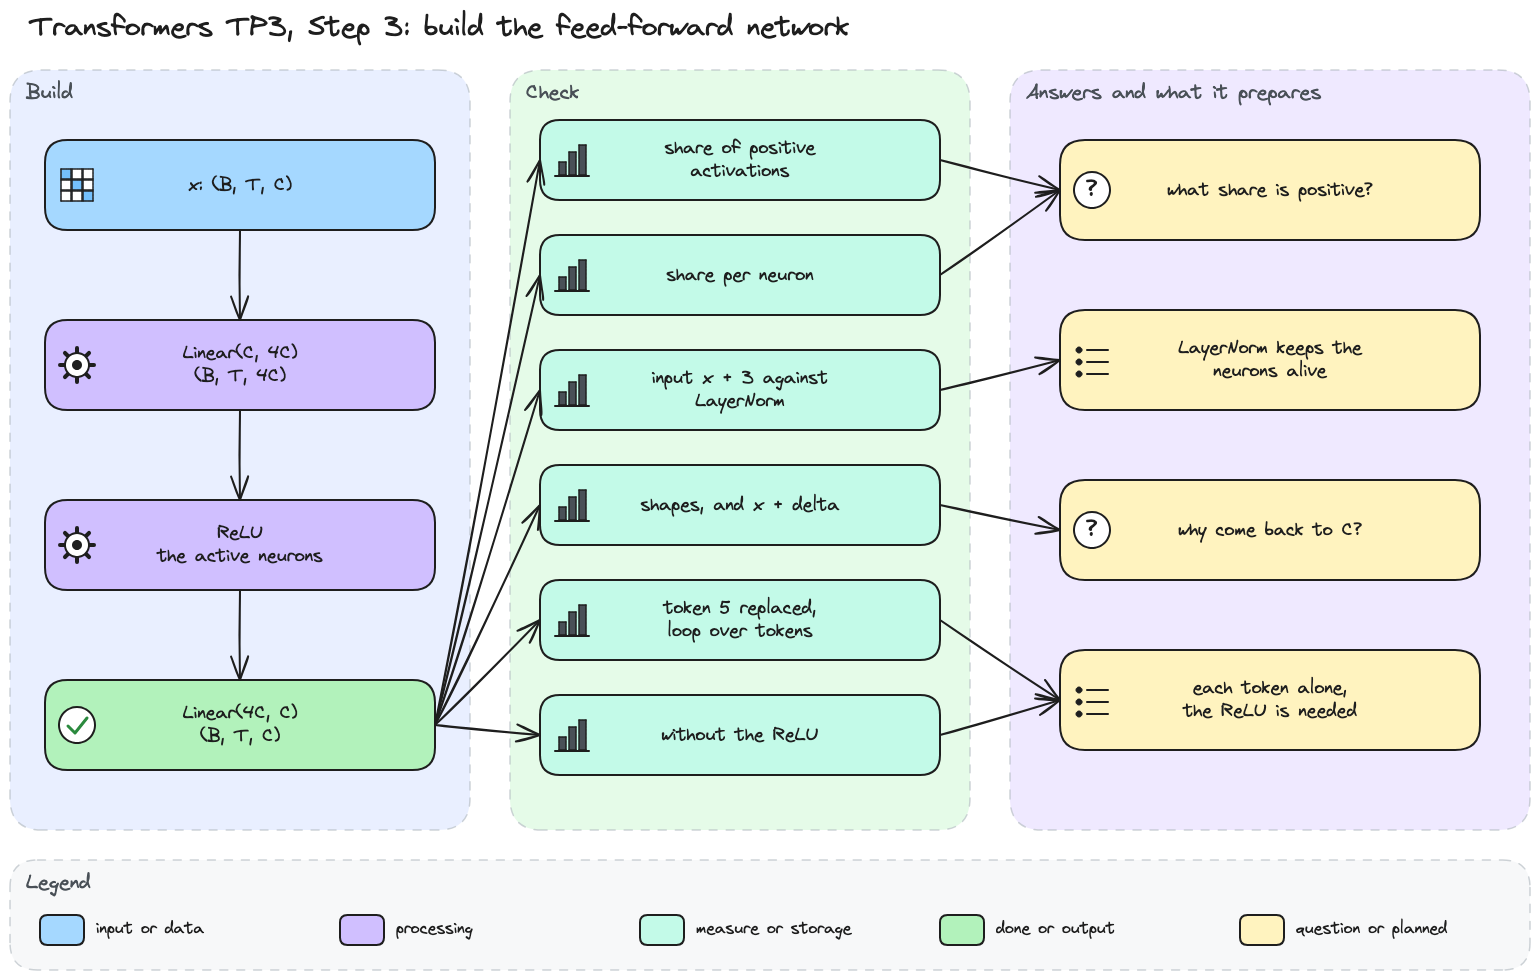

In [19]:
# Step 3 diagram: the network C -> 4C -> C, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp3_step3.png', width=900))

In [20]:
# The feed-forward network: widen each token to 4C, apply ReLU, come back to C.
class FeedForward(nn.Module):
    """Linear C to 4C, ReLU, then Linear 4C to C, on the last dimension of x."""

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
        )

    def forward(self, x):
        return self.net(x)

I fill the blanks with `4 * n_embd` on both sides of the ReLU, and `forward` only calls `self.net`. `nn.Linear` acts on the last dimension, so a tensor (B, T, C) should go through without any reshape. I run the handout cell with seed 1337, as in section 2, so the draw does not depend on the cells above.

In [21]:
# The handout cell, with a seed so that the draw does not depend on the cells above.
torch.manual_seed(1337)
ffwd = FeedForward(100)
delta = ffwd(torch.randn(32, 100))
print(delta.shape)

torch.Size([32, 100])


`delta` has the shape (32, 100), the same as the 32 tokens of 100 components that went in. In between, the network widened every token to 400 values, and I want to see what the ReLU did there.

In [22]:
# What share of the hidden activations is positive? The same draw, read before and after the ReLU.
torch.manual_seed(1337)
ffwd = FeedForward(100)
tokens = torch.randn(32, 100)
print(f'Same delta as the handout cell: {torch.equal(ffwd(tokens), delta)}')

pre = ffwd.net[0](tokens)  # after Linear(C, 4C), before the ReLU
hidden = ffwd.net[1](pre)
print(f'Before the ReLU: {tuple(pre.shape)}, mean {pre.mean():.3f}, std {pre.std():.3f}')
print(f'After the ReLU: positive {100 * (hidden > 0).float().mean():.2f}%, '
      f'exactly zero {100 * (hidden == 0).float().mean():.2f}% of {hidden.numel():,} values')

Same delta as the handout cell: True
Before the ReLU: (32, 400), mean 0.008, std 0.565
After the ReLU: positive 50.74%, exactly zero 49.26% of 12,800 values


Before the ReLU, the 400 hidden values of each token have a mean of 0.008 and a std of 0.565, so they sit around 0. The ReLU keeps the positive ones and sets the others to exactly 0. So 50.74% of the 12,800 activations are positive and 49.26% are zeros, and my hypothesis of about half holds.

A global share could still hide neurons that never fire, so I look neuron by neuron.

Per neuron: from 21.88% to 78.12%, never active 0, always active 0
Per token: from 45.50% to 56.75% of the 400 neurons


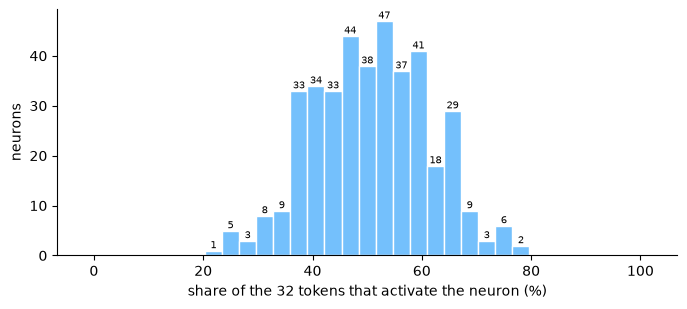

In [23]:
# Is it the same half for every token? Share of the 32 tokens that activate each of the 400 neurons.
EDGES = [100 * (k - 0.5) / 32 for k in range(34)]  # one bin per possible share, k / 32
active = (hidden > 0).float()
per_neuron, per_token = active.mean(dim=0), active.mean(dim=1)
print(f'Per neuron: from {100 * per_neuron.min():.2f}% to {100 * per_neuron.max():.2f}%, '
      f'never active {(per_neuron == 0).sum().item()}, '
      f'always active {(per_neuron == 1).sum().item()}')
print(f'Per token: from {100 * per_token.min():.2f}% to {100 * per_token.max():.2f}% '
      f'of the 400 neurons')

fig, ax = plt.subplots(figsize=(8, 3.2))
counts, _, bars = ax.hist(100 * per_neuron, bins=EDGES, color='#74c0fc', edgecolor='white')
ax.bar_label(bars, labels=[int(c) if c else '' for c in counts], fontsize=7)
ax.set_xlabel('share of the 32 tokens that activate the neuron (%)')
ax.set_ylabel('neurons')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Each of the 400 neurons fires for between 21.88% and 78.12% of the 32 tokens, and the histogram is centred near 50%. No neuron is never active and none is always active. Each token switches on between 45.50% and 56.75% of the neurons, so every token uses about half of the network, a different half each time. A neuron that never fires gets no gradient through the ReLU, so this balance is what I want before training.

The input came from `randn`, centred on 0. I want to know what happens when it is shifted.

tokens: 50.74% active, never active 0, always active 0
tokens + 3: 47.59% active, never active 93, always active 100
my LayerNorm(tokens + 3): 50.77% active, never active 0, always active 0


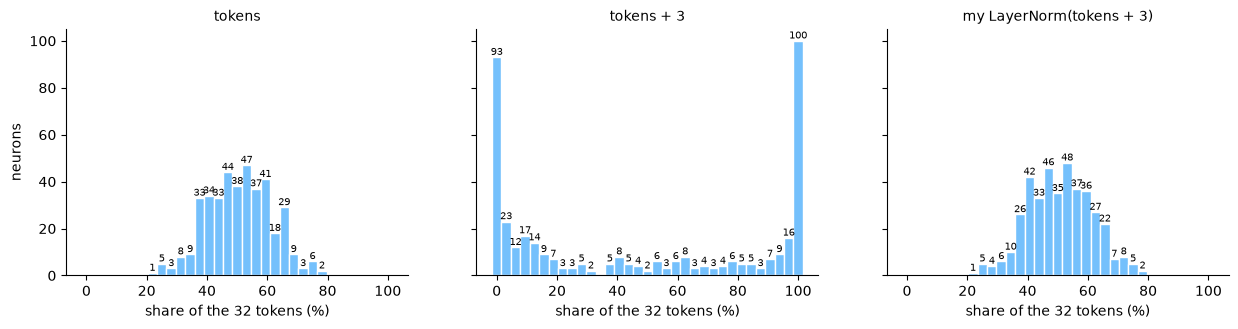

In [24]:
# Does the input offset matter? Active share per neuron for three versions of the same tokens.
inputs = {'tokens': tokens, 'tokens + 3': tokens + 3,
          'my LayerNorm(tokens + 3)': module(tokens + 3)}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for ax, (name, z) in zip(axes, inputs.items()):
    share = (ffwd.net[1](ffwd.net[0](z)) > 0).float().mean(dim=0)
    print(f'{name}: {100 * share.mean():.2f}% active, never active {(share == 0).sum().item()}, '
          f'always active {(share == 1).sum().item()}')
    counts, _, bars = ax.hist(100 * share, bins=EDGES, color='#74c0fc', edgecolor='white')
    ax.bar_label(bars, labels=[int(c) if c else '' for c in counts], fontsize=7)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('share of the 32 tokens (%)')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('neurons')
plt.show()

Adding 3 to every component splits the neurons. 93 of them never fire on any of the 32 tokens and 100 always fire, while the overall share only moves to 47.59%. A neuron that never fires passes nothing and gets no gradient, and one that always fires behaves like a plain linear unit.

My LayerNorm on the same shifted tokens brings back 0 dead and 0 always-active neurons, with 50.77% active. So the LayerNorm placed before this network, the pre-norm order of section 4, keeps its neurons in their useful range.

In [25]:
# Why come back to C? The shape after each layer on (B, T, C), then x + hidden against x + delta.
B, T, C = 4, 8, 100
x = torch.randn(B, T, C)
print(f'x: {tuple(x.shape)}')
h = x
for layer in ffwd.net:
    h = layer(h)
    print(f'after {layer}: {tuple(h.shape)}')

try:
    x + ffwd.net[1](ffwd.net[0](x))
except RuntimeError as error:
    print(f'x + hidden at 4C fails: {error}')
print(f'x + ffwd(x): {tuple((x + ffwd(x)).shape)}')

x: (4, 8, 100)
after Linear(in_features=100, out_features=400, bias=True): (4, 8, 400)
after ReLU(): (4, 8, 400)
after Linear(in_features=400, out_features=100, bias=True): (4, 8, 100)
x + hidden at 4C fails: The size of tensor a (100) must match the size of tensor b (400) at non-singleton dimension 2
x + ffwd(x): (4, 8, 100)


Each `nn.Linear` acts on the last dimension only, so (4, 8, 100) becomes (4, 8, 400), then (4, 8, 100), without any reshape. Adding the hidden layer at 4C to `x` fails, since 100 and 400 do not match in dimension 2. Coming back to C gives `delta` the shape of `x`, so `x + delta` works.

That addition is the residual connection of section 4. The head of TP2 returned 16 channels for C = 32, so it would meet the same mismatch.

Largest change per row of the first sequence: [0.0, 0.0, 0.0, 0.0, 0.0, 0.69, 0.0, 0.0]
Whole tensor against one token at a time: largest gap 4.2e-07, allclose True


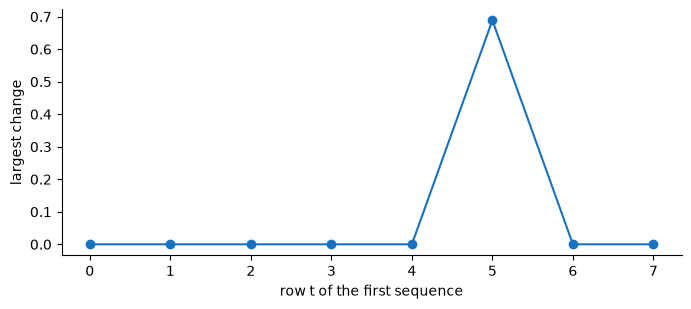

In [26]:
# Does the network mix tokens? Token 5 of the first sequence replaced, then one token at a time.
changed = x.clone()
changed[0, 5] = torch.randn(C)
moves = (ffwd(changed) - ffwd(x))[0].abs().max(dim=-1).values.detach()
print(f'Largest change per row of the first sequence: {[round(v, 2) for v in moves.tolist()]}')

one_by_one = torch.stack([torch.stack([ffwd(x[b, t]) for t in range(T)]) for b in range(B)])
print(f'Whole tensor against one token at a time: largest gap '
      f'{(one_by_one - ffwd(x)).abs().max():.1e}, '
      f'allclose {torch.allclose(one_by_one, ffwd(x), atol=1e-6)}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(T), moves, marker='o', color='#1971c2')
ax.set_xlabel('row t of the first sequence')
ax.set_ylabel('largest change')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Replacing token 5 of the first sequence moves row 5 by 0.69 and leaves the seven other rows at 0.0. Running the network on the whole tensor or one token at a time gives the same result within 4.2e-07, with allclose True. So the network applies the same function to each token, and my hypothesis that the MLP does not mix tokens holds.

Mixing is the job of attention, and this network then works on what each token has gathered. Its ReLU is the one part I have not justified yet.

In [27]:
# Is the ReLU needed? Without it, the two Linear layers should be a single Linear(C, C).
up, down = ffwd.net[0], ffwd.net[2]
weight = down.weight @ up.weight  # (C, 4C) @ (4C, C)
bias = down.weight @ up.bias + down.bias
print(f'Merged weight: {tuple(weight.shape)}, rank {torch.linalg.matrix_rank(weight).item()}')
print(f'Two Linear layers without ReLU against x @ weight.T + bias: largest gap '
      f'{(down(up(x)) - (x @ weight.T + bias)).abs().max():.1e}')

Merged weight: (100, 100), rank 100
Two Linear layers without ReLU against x @ weight.T + bias: largest gap 8.9e-07


Without the ReLU, the two layers give the same output as one merged weight within 8.9e-07. The merged weight is a plain (100, 100) matrix of rank 100, so the pair is one ordinary Linear(C, C). The 400 hidden values would add parameters and no new kind of function.

I want to measure how far the ReLU takes the network from a linear map.

In [28]:
# How far from linear is the network? The best linear fit on 2,000 random tokens.
torch.manual_seed(RANDOM_STATE)
sample = torch.randn(2000, C)
design = torch.cat([sample, torch.ones(2000, 1)], dim=1)  # a column of ones for the bias
for name, network in (('with ReLU', ffwd), ('without ReLU', lambda z: down(up(z)))):
    target = network(sample).detach()
    fit = design @ torch.linalg.lstsq(design, target).solution
    print(f'{name}: {100 * (fit - target).var() / target.var():.2f}% of the variance '
          f'left unexplained by the best linear map')

with ReLU: 16.64% of the variance left unexplained by the best linear map
without ReLU: 0.00% of the variance left unexplained by the best linear map


On 2,000 random tokens, the best linear map leaves 16.64% of the variance of the ReLU network unexplained, against 0.00% without the ReLU. Even untrained, about a sixth of the output is out of reach of a single matrix. Training will decide how much of this non-linear part the network uses.

> *My conclusion:*
>
> My `FeedForward` widens each token from C = 100 to 400 values, cuts the negative ones with a ReLU and comes back to 100. Before training, 50.74% of the hidden activations are positive, and every neuron fires for between 21.88% and 78.12% of the tokens. My hypothesis of about half holds. The LayerNorm in front matters, since a shift of 3 left 93 neurons dead and 100 always active.
>
> The network acts on each token alone, so it does not mix positions. Without the ReLU it would collapse into one Linear(C, C), and with it 16.64% of its output escapes the best linear map. Section 4 adds its output back to the input in the pre-norm block.
>
> My answers to the two questions of this step:
>
> 1. 50.74% of the 12,800 hidden activations are positive, and the other 49.26% are exactly 0.
> 2. The network comes back to C so that `delta` has the shape of `x`. `x + delta` then works for the residual, while `x` plus the hidden layer at 4C fails.

## 4. Add the residual connection

Sections 1 to 3 built the two pieces. I now chain them in the pre-norm order, LayerNorm before the feed-forward network, and add the result back to the input. I want to know what this addition keeps of the input and what it changes for the gradient.

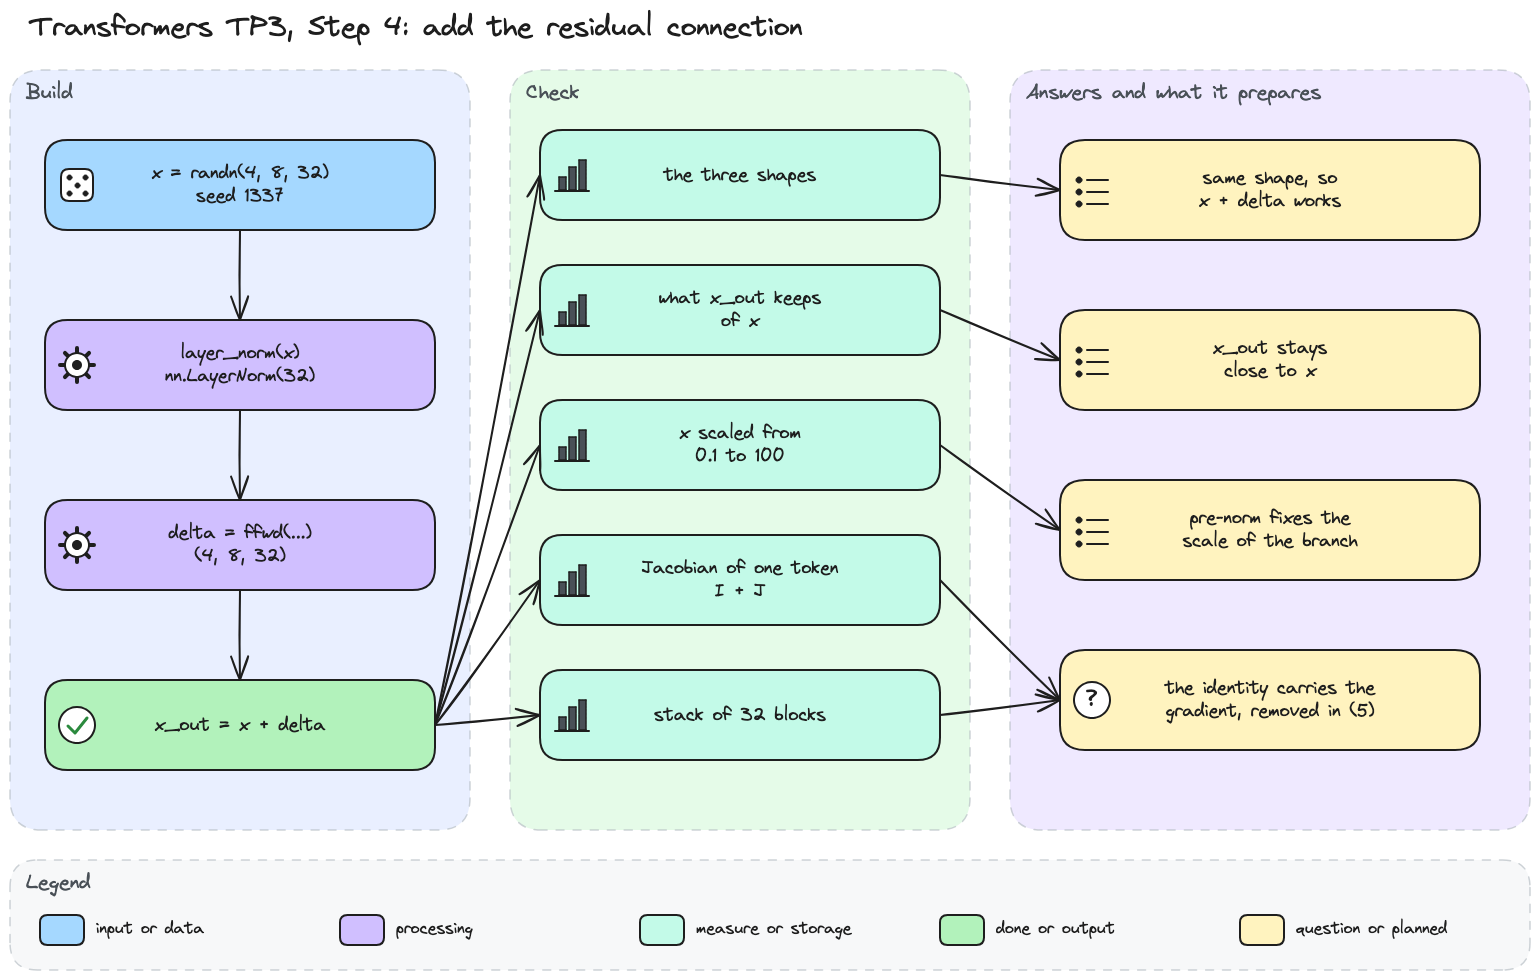

In [29]:
# Step 4 diagram: the pre-norm block, and the checks around its residual addition.
display(Image(filename='diagrams/transformers/tp3_step4.png', width=900))

The handout leaves B, T and n_embd open. I take 4, 8 and 32, the shapes of my TP2 head, with seed 1337. I use `nn.LayerNorm` here, since my own class matched it within 4.8e-07 in section 2.

In [30]:
# The pre-norm block: LayerNorm, then the feed-forward network, then the residual addition.
torch.manual_seed(1337)
B, T, n_embd = 4, 8, 32
layer_norm = nn.LayerNorm(n_embd)
ffwd = FeedForward(n_embd)

x = torch.randn(B, T, n_embd)
delta = ffwd(layer_norm(x))
x_out = x + delta

print(x.shape)
print(delta.shape)
print(x_out.shape)

torch.Size([4, 8, 32])
torch.Size([4, 8, 32])
torch.Size([4, 8, 32])


`x`, `delta` and `x_out` all have the shape (4, 8, 32). The feed-forward network came back to C in section 3, so the addition works without any reshape. Equal shapes do not tell me how much `delta` changes `x`, so I measure it token by token.

std of x 0.97, of delta 0.24, of x_out 1.00
||delta|| / ||x|| per token: from 17.02% to 38.15%, mean 25.39%
cosine(x_out, x) per token: from 0.941 to 0.986


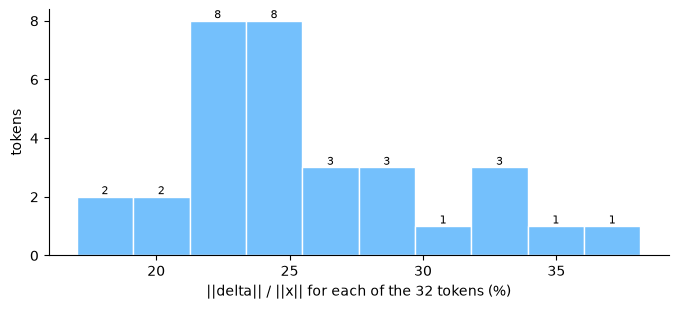

In [31]:
# How much does the block change each token? Sizes of x, delta and x_out, token by token.
import torch.nn.functional as F

share = (delta.norm(dim=-1) / x.norm(dim=-1)).flatten().detach()
cosine = F.cosine_similarity(x_out, x, dim=-1).flatten().detach()
print(f'std of x {x.std():.2f}, of delta {delta.std():.2f}, of x_out {x_out.std():.2f}')
print(f'||delta|| / ||x|| per token: from {100 * share.min():.2f}% to {100 * share.max():.2f}%, '
      f'mean {100 * share.mean():.2f}%')
print(f'cosine(x_out, x) per token: from {cosine.min():.3f} to {cosine.max():.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
counts, _, bars = ax.hist(100 * share, bins=10, color='#74c0fc', edgecolor='white')
ax.bar_label(bars, labels=[int(c) if c else '' for c in counts], fontsize=8)
ax.set_xlabel('||delta|| / ||x|| for each of the 32 tokens (%)')
ax.set_ylabel('tokens')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

`x` has a std of 0.97, `delta` 0.24 and `x_out` 1.00. Per token, the length ||delta|| of `delta` is between 17.02% and 38.15% of the length of `x`, 25.39% on average. The cosine between `x_out` and `x` stays between 0.941 and 0.986, so each token keeps its direction.

My hypothesis that `x_out` stays close to `x` at initialisation holds. The block starts as a small correction added to an untouched copy of the input.

x * 0.1: std of delta 0.238, ||delta|| / ||x|| 253.75%
x * 1: std of delta 0.238, ||delta|| / ||x|| 25.39%
x * 10: std of delta 0.238, ||delta|| / ||x|| 2.54%
x * 100: std of delta 0.238, ||delta|| / ||x|| 0.25%


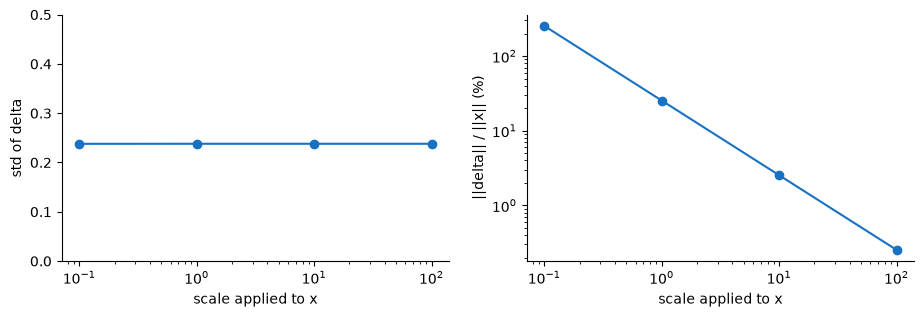

In [32]:
# Does the branch follow the scale of x? The same tokens scaled from 0.1 to 100.
SCALES = [0.1, 1, 10, 100]
delta_stds, shares = [], []
for s in SCALES:
    scaled_delta = ffwd(layer_norm(x * s))
    delta_stds.append(scaled_delta.std().item())
    shares.append(100 * (scaled_delta.norm(dim=-1) / (x * s).norm(dim=-1)).mean().item())
    print(f'x * {s:g}: std of delta {delta_stds[-1]:.3f}, ||delta|| / ||x|| {shares[-1]:.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, values, label in ((axes[0], delta_stds, 'std of delta'),
                          (axes[1], shares, '||delta|| / ||x|| (%)')):
    ax.plot(SCALES, values, marker='o', color='#1971c2')
    ax.set_xscale('log')
    ax.set_xlabel('scale applied to x')
    ax.set_ylabel(label)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylim(0, 0.5)
axes[1].set_yscale('log')
plt.show()

Whatever the scale of `x`, `delta` keeps a std of 0.238, because LayerNorm hands the network the same normalised tokens. Its share of `x` then falls from 253.75% at a scale of 0.1 to 0.25% at a scale of 100.

In the pre-norm order, the branch always works at a fixed scale, and the residual stream keeps its own. A large stream would barely move under one block, which I keep in mind for a stack of blocks.

block, v + ffwd(layer_norm(v)): diagonal mean 1.0006, singular values from 0.65 to 1.49
branch alone, ffwd(layer_norm(v)): diagonal mean 0.0006, singular values from 0.00 to 0.60


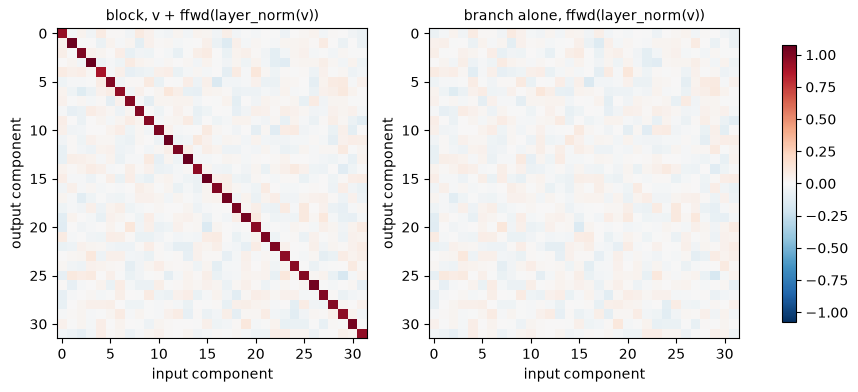

In [33]:
# How does a gradient cross the block? Jacobian of one token, through the block and the branch.
token = x[0, 0]
jacobians = {
    'block, v + ffwd(layer_norm(v))': torch.autograd.functional.jacobian(
        lambda v: v + ffwd(layer_norm(v)), token),
    'branch alone, ffwd(layer_norm(v))': torch.autograd.functional.jacobian(
        lambda v: ffwd(layer_norm(v)), token),
}
for name, jacobian in jacobians.items():
    singular = torch.linalg.svdvals(jacobian)
    print(f'{name}: diagonal mean {jacobian.diagonal().mean():.4f}, '
          f'singular values from {singular.min():.2f} to {singular.max():.2f}')

limit = max(jacobian.abs().max().item() for jacobian in jacobians.values())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, jacobian) in zip(axes, jacobians.items()):
    image = ax.imshow(jacobian, cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('input component')
    ax.set_ylabel('output component')
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

The Jacobian tells how much each output component moves when one input component moves. For the block, it is the identity plus a faint cloud, with a diagonal mean of 1.0006 and singular values from 0.65 to 1.49. The branch alone has a diagonal mean of 0.0006 and singular values from 0.00 to 0.60.

A singular value of 0.00 means that some input directions never reach the output of the branch, since LayerNorm drops the mean and the scale of each token. Through the block, the added identity lets every direction of the gradient through with a factor of at least 0.65.

depth 1: std of the stream 1.00, gradient at x / ||g|| 1.03, cosine to x 0.97
depth 4: std of the stream 1.10, gradient at x / ||g|| 1.17, cosine to x 0.90
depth 8: std of the stream 1.19, gradient at x / ||g|| 1.27, cosine to x 0.83
depth 16: std of the stream 1.39, gradient at x / ||g|| 1.52, cosine to x 0.71
depth 32: std of the stream 1.67, gradient at x / ||g|| 1.77, cosine to x 0.60


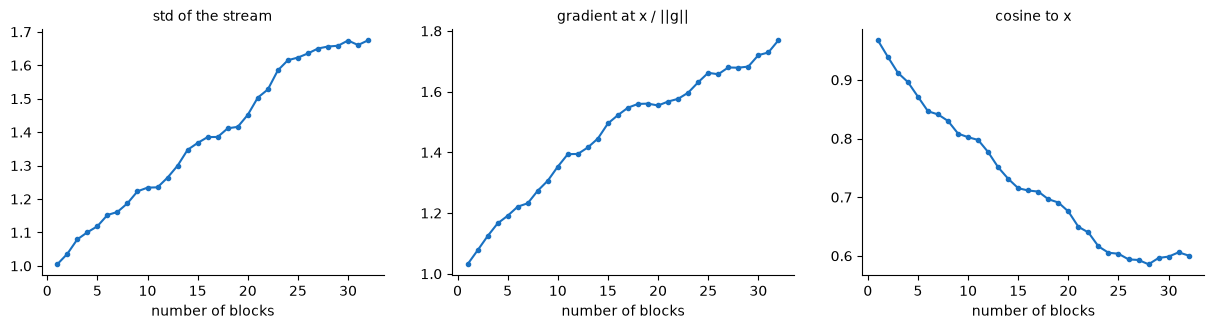

In [34]:
# What happens across many blocks? 32 pre-norm blocks with fresh weights, depth by depth.
torch.manual_seed(RANDOM_STATE)
blocks = [(nn.LayerNorm(n_embd), FeedForward(n_embd)) for _ in range(32)]
g = torch.randn(B, T, n_embd)  # a fixed direction for the gradient, loss = (z * g).sum()
history = {'std of the stream': [], 'gradient at x / ||g||': [], 'cosine to x': []}
for depth in range(1, 33):
    start = x.detach().clone().requires_grad_()
    z = start
    for norm_layer, network in blocks[:depth]:
        z = z + network(norm_layer(z))
    (z * g).sum().backward()
    history['std of the stream'].append(z.std().item())
    history['gradient at x / ||g||'].append((start.grad.norm() / g.norm()).item())
    history['cosine to x'].append(F.cosine_similarity(z.flatten(), x.flatten(), dim=0).item())
for depth in (1, 4, 8, 16, 32):
    print(f'depth {depth}: '
          + ', '.join(f'{name} {values[depth - 1]:.2f}' for name, values in history.items()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, (name, values) in zip(axes, history.items()):
    ax.plot(range(1, 33), values, marker='o', markersize=3, color='#1971c2')
    ax.set_xlabel('number of blocks')
    ax.set_title(name, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

Across 32 blocks, the std of the stream grows from 1.00 to 1.67, since each block adds its own `delta` on top. The gradient that reaches `x` also grows, from 1.03 to 1.77 times ||g||, because every block passes it through the identity before its own branch. The cosine to `x` falls from 0.97 to 0.60, so the stream drifts away from the input while still holding a large part of it.

Section 5 removes the addition to see what is lost without this path.

> *My conclusion:*
>
> The pre-norm block keeps the shape (4, 8, 32), so `x_out = x + delta` needs no reshape. At initialisation `delta` is 25.39% of `x` on average and the cosine between `x_out` and `x` stays above 0.94, so my hypothesis holds. LayerNorm gives the branch the same scale for any input, with a std of 0.238 for `delta`, while the stream keeps its own scale.
>
> The addition puts an identity in the Jacobian of the block, with singular values of at least 0.65 where the branch alone reaches 0.00. Across 32 blocks the gradient at `x` stays between 1.03 and 1.77 times ||g||, and the stream still holds part of the input, with a cosine of 0.60. Section 5 tests the variants and removes the addition to measure what it brings.

## 5. Test variants

The block of section 4 works, and I now change one piece at a time to see what each choice brings. I try GELU in place of ReLU, hidden widths of 2C and 8C with their parameter counts, then I remove the residual addition.

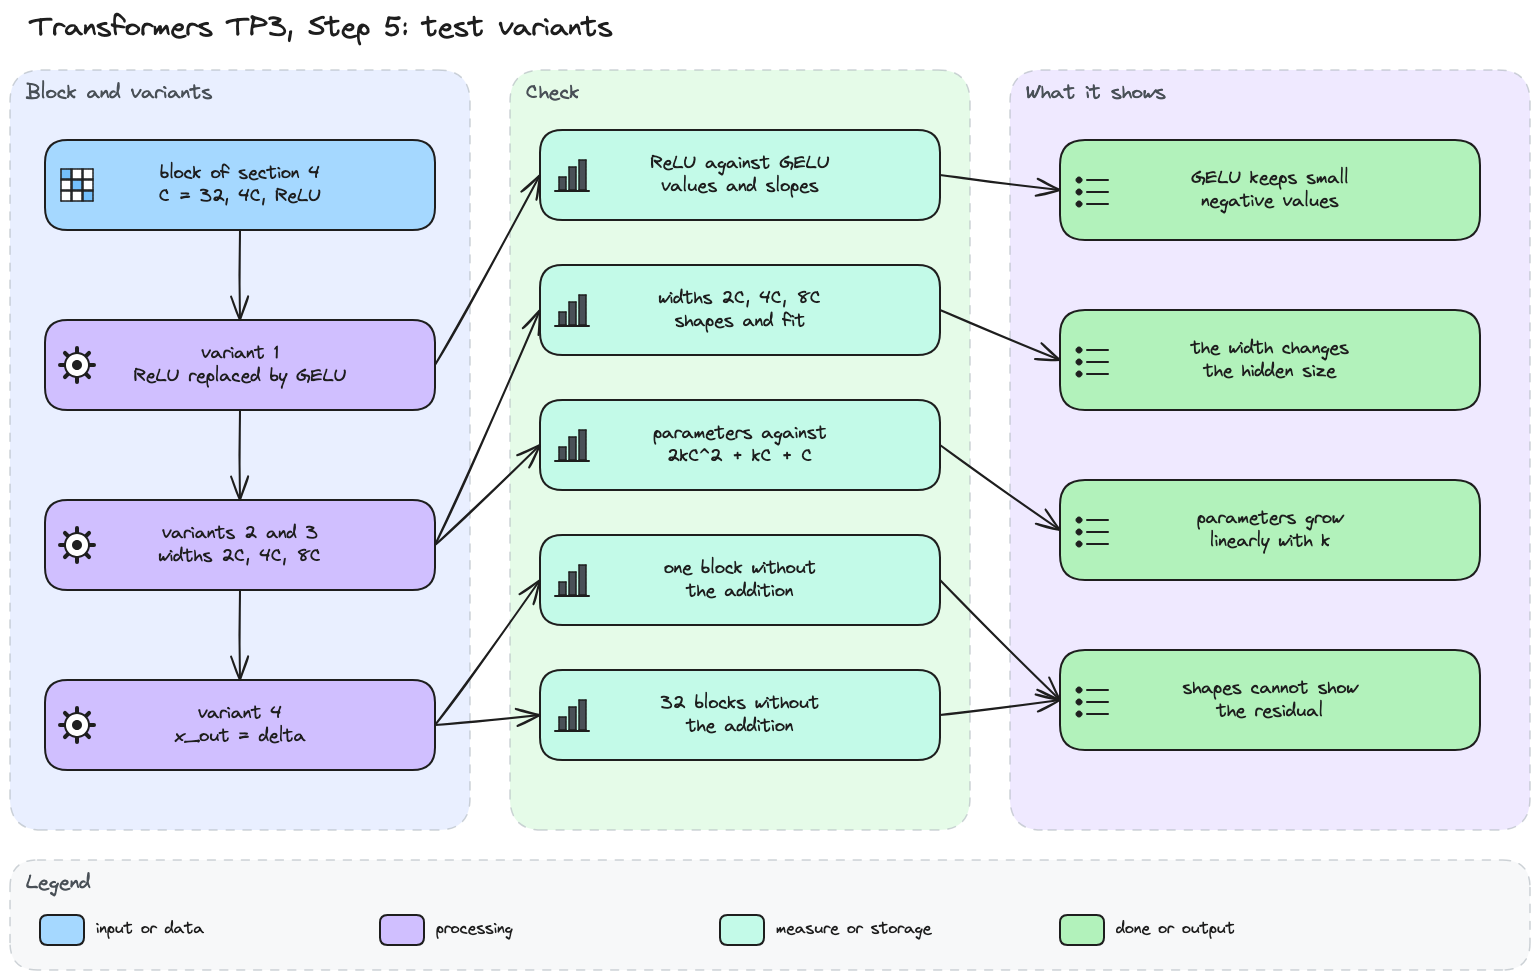

In [35]:
# Step 5 diagram: the four variants of the block, and what each one shows.
display(Image(filename='diagrams/transformers/tp3_step5.png', width=900))

In [36]:
# Variant 1: GELU in place of ReLU, with the same weights as the block of section 4.
import copy

gelu_ffwd = copy.deepcopy(ffwd)
gelu_ffwd.net[1] = nn.GELU()
delta_gelu = gelu_ffwd(layer_norm(x))
print(f'delta with GELU: {tuple(delta_gelu.shape)}, std {delta_gelu.std():.3f} '
      f'against {delta.std():.3f} with ReLU')
print(f'Largest gap with the ReLU delta: {(delta_gelu - delta).abs().max():.2f}')

delta with GELU: (4, 8, 32), std 0.208 against 0.238 with ReLU
Largest gap with the ReLU delta: 0.22


With the same weights, GELU gives a `delta` of the same shape (4, 8, 32), with a std of 0.208 against 0.238 for ReLU. The two outputs differ by up to 0.22, so the activation alone changes what the block adds. I want to see where the two functions differ.

ReLU on the hidden values: zeros 49.80%, negatives 0.00%, zero slopes 49.80%, minimum 0.000
GELU on the hidden values: zeros 0.00%, negatives 49.80%, zero slopes 0.00%, minimum -0.170


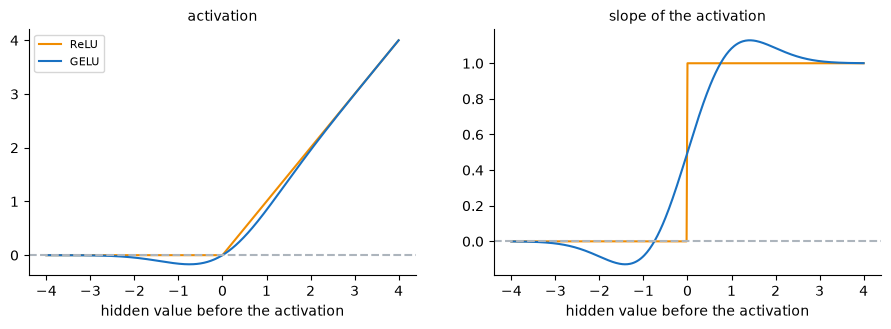

In [37]:
# Where do ReLU and GELU differ? Their values and slopes, then their effect on the hidden values.
grid = torch.linspace(-4, 4, 401, requires_grad=True)
hidden_pre = ffwd.net[0](layer_norm(x)).detach()  # the 128 hidden values of each token
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for activation, color in ((nn.ReLU(), '#f08c00'), (nn.GELU(), '#1971c2')):
    name = activation.__class__.__name__
    values = activation(grid)
    slope, = torch.autograd.grad(values.sum(), grid)
    axes[0].plot(grid.detach(), values.detach(), color=color, label=name)
    axes[1].plot(grid.detach(), slope, color=color, label=name)
    pre = hidden_pre.clone().requires_grad_()
    out = activation(pre)
    pre_slope, = torch.autograd.grad(out.sum(), pre)
    print(f'{name} on the hidden values: zeros {100 * (out == 0).float().mean():.2f}%, '
          f'negatives {100 * (out < 0).float().mean():.2f}%, '
          f'zero slopes {100 * (pre_slope == 0).float().mean():.2f}%, minimum {out.min():.3f}')
for ax, title in ((axes[0], 'activation'), (axes[1], 'slope of the activation')):
    ax.axhline(0, linestyle='--', color='#adb5bd')
    ax.set_xlabel('hidden value before the activation')
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

Far from 0 the two curves agree, and they differ around 0. ReLU cuts every negative hidden value to 0, so 49.80% of the hidden values are zeros with a slope of 0. GELU keeps them as small negatives, down to −0.170, and none of its slopes is exactly 0.

A neuron that gets a negative input still passes a little gradient with GELU, which avoids the dead neurons I feared in section 3. Its slope even goes slightly below 0 for inputs between about −3 and −1.

2C: hidden (4, 8, 64), output (4, 8, 32), delta std 0.255, positive 48.97%, unexplained by a linear map 14.71%
4C: hidden (4, 8, 128), output (4, 8, 32), delta std 0.230, positive 51.39%, unexplained by a linear map 18.04%
8C: hidden (4, 8, 256), output (4, 8, 32), delta std 0.242, positive 51.18%, unexplained by a linear map 17.11%


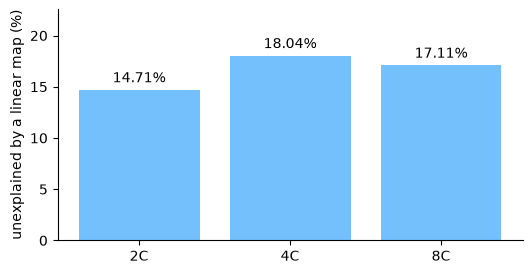

In [38]:
# Variant 2: hidden widths 2C, 4C and 8C. What changes besides the hidden size?
torch.manual_seed(RANDOM_STATE)
FACTORS = [2, 4, 8]
widths = {k: nn.Sequential(nn.Linear(n_embd, k * n_embd), nn.ReLU(), nn.Linear(k * n_embd, n_embd))
          for k in FACTORS}
sample = torch.randn(2000, n_embd)
design = torch.cat([sample, torch.ones(2000, 1)], dim=1)  # a column of ones for the bias
unexplained = []
for k, net in widths.items():
    hidden_k = net[1](net[0](layer_norm(x)))
    out_k = net(layer_norm(x))
    target = net(sample).detach()
    fit = design @ torch.linalg.lstsq(design, target).solution
    unexplained.append(100 * ((fit - target).var() / target.var()).item())
    print(f'{k}C: hidden {tuple(hidden_k.shape)}, output {tuple(out_k.shape)}, '
          f'delta std {out_k.std():.3f}, positive {100 * (hidden_k > 0).float().mean():.2f}%, '
          f'unexplained by a linear map {unexplained[-1]:.2f}%')

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar([f'{k}C' for k in FACTORS], unexplained, color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in unexplained], padding=3)
ax.set_ylabel('unexplained by a linear map (%)')
ax.set_ylim(0, max(unexplained) * 1.25)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The hidden size follows the factor, (4, 8, 64), (4, 8, 128) and (4, 8, 256), while the output stays (4, 8, 32). So the width only changes what happens inside the network.

The std of `delta` stays between 0.230 and 0.255 and the positive share between 48.97% and 51.39%, with no trend. The share left unexplained by a linear map goes 14.71%, 18.04% and 17.11%, so a wider layer is not clearly more non-linear before training. With one seed, these small gaps may come from the random weights, and the cost of width shows up in the parameters.

2C: 4,192 parameters, 2kC² + kC + C = 4,192
4C: 8,352 parameters, 2kC² + kC + C = 8,352
8C: 16,672 parameters, 2kC² + kC + C = 16,672
LayerNorm(32): 64, TP2 head: 1,536 parameters


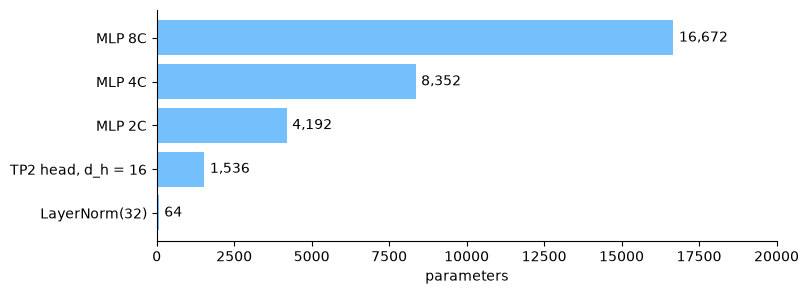

In [39]:
# Variant 3: parameters of each width against 2kC² + kC + C, next to the other pieces I built.
counts = {f'MLP {k}C': sum(p.numel() for p in net.parameters()) for k, net in widths.items()}
for k in FACTORS:
    formula = 2 * k * n_embd**2 + k * n_embd + n_embd
    print(f'{k}C: {counts[f"MLP {k}C"]:,} parameters, 2kC² + kC + C = {formula:,}')
head = [nn.Linear(n_embd, 16, bias=False) for _ in range(3)]  # key, query, value of my TP2 head
counts = {'LayerNorm(32)': sum(p.numel() for p in layer_norm.parameters()),
          'TP2 head, d_h = 16': sum(p.numel() for layer in head for p in layer.parameters()),
          **counts}
print(f'LayerNorm(32): {counts["LayerNorm(32)"]:,}, '
      f'TP2 head: {counts["TP2 head, d_h = 16"]:,} parameters')

fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(list(counts), list(counts.values()), color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:,}' for value in counts.values()], padding=4)
ax.set_xlim(0, max(counts.values()) * 1.2)
ax.set_xlabel('parameters')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Each count matches 2kC² + kC + C, with 4,192, 8,352 and 16,672 parameters. Going from 2C to 4C adds 4,160 parameters and going from 4C to 8C adds 8,320, twice as many for a step twice as large. So the count grows linearly with k, by 2C² + C = 2,080 per unit, plus the 32 biases of the output layer. The first half of my last hypothesis holds.

At 4C the MLP already holds 8,352 parameters, more than five times my TP2 head (1,536) and 130 times LayerNorm (64).

In [40]:
# Variant 4: the block without its residual addition. Do the shapes reveal it?
x_out_plain = delta  # ffwd(layer_norm(x)), without + x
print(f'x: {tuple(x.shape)}, delta: {tuple(delta.shape)}, '
      f'x_out without the addition: {tuple(x_out_plain.shape)}')
for name, output in (('with the addition', x_out), ('without the addition', x_out_plain)):
    print(f'{name}: mean cosine to x {F.cosine_similarity(output, x, dim=-1).mean():.3f}')

x: (4, 8, 32), delta: (4, 8, 32), x_out without the addition: (4, 8, 32)
with the addition: mean cosine to x 0.969
without the addition: mean cosine to x 0.023


Without the addition, `x_out` is `delta` itself, and its shape is still (4, 8, 32), the same as `x`. So the shapes cannot show whether the residual is there, and the second half of my last hypothesis holds. The mean cosine to `x` drops from 0.969 to 0.023, so the output keeps almost nothing of the input direction.

I want to see what this does over many blocks.

depth 1: std of the stream 0.25, gradient at x / ||g|| 0.24, cosine to x 0.01
depth 4: std of the stream 0.23, gradient at x / ||g|| 0.20, cosine to x -0.00
depth 8: std of the stream 0.22, gradient at x / ||g|| 0.30, cosine to x 0.11
depth 16: std of the stream 0.24, gradient at x / ||g|| 0.26, cosine to x -0.00
depth 32: std of the stream 0.22, gradient at x / ||g|| 0.30, cosine to x 0.02


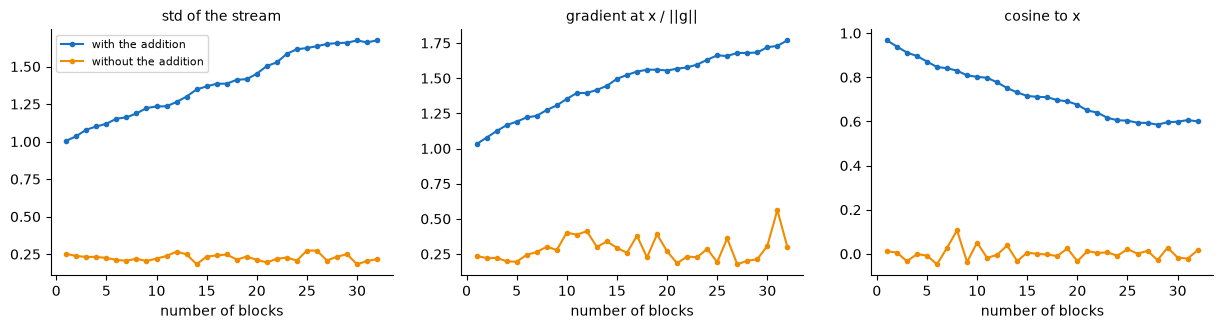

In [41]:
# What does a stack lose without the addition? The 32 blocks of section 4, rerun without it.
history_plain = {name: [] for name in history}
for depth in range(1, 33):
    start = x.detach().clone().requires_grad_()
    z = start
    for norm_layer, network in blocks[:depth]:
        z = network(norm_layer(z))  # no residual addition
    (z * g).sum().backward()
    history_plain['std of the stream'].append(z.std().item())
    history_plain['gradient at x / ||g||'].append((start.grad.norm() / g.norm()).item())
    history_plain['cosine to x'].append(F.cosine_similarity(z.flatten(), x.flatten(), dim=0).item())
for depth in (1, 4, 8, 16, 32):
    print(f'depth {depth}: '
          + ', '.join(f'{name} {values[depth - 1]:.2f}' for name, values in history_plain.items()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, name in zip(axes, history):
    ax.plot(range(1, 33), history[name], marker='o', markersize=3, color='#1971c2',
            label='with the addition')
    ax.plot(range(1, 33), history_plain[name], marker='o', markersize=3, color='#f08c00',
            label='without the addition')
    ax.set_xlabel('number of blocks')
    ax.set_title(name, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

Without the addition, the stream stays at a std between 0.22 and 0.25, since every block starts with a LayerNorm. The cosine to `x` sits around 0 from the first block, at most 0.11 at the depths I print, so the input is gone after one block. The gradient that reaches `x` stays between 0.20 and 0.30 times ||g||, against 1.03 to 1.77 with the addition.

The addition keeps the input in the stream and gives the gradient a direct path back to it.

> *My conclusion:*
>
> Each variant changes one piece of the block and keeps its shape (4, 8, 32). GELU keeps small negative values where ReLU gives zeros, the width sets the hidden size and the parameter count, and the addition decides whether the input survives. My last hypothesis holds, with 2,080 more parameters per unit of k and a shape that stays (4, 8, 32) without the residual.
>
> My results for the four variants of this step:
>
> 1. GELU in place of ReLU moves `delta` by up to 0.22 and leaves no hidden value at exactly 0, against 49.80% with ReLU.
> 2. Widths 2C, 4C and 8C give hidden sizes 64, 128 and 256 and the same output (4, 8, 32), with no clear trend in my measures.
> 3. They count 4,192, 8,352 and 16,672 parameters, exactly 2kC² + kC + C.
> 4. Without the residual the shapes stay (4, 8, 32), but the cosine to `x` falls from 0.969 to 0.023. Over 32 blocks the gradient at `x` stays at or below 0.30 times ||g||.

## Summary

I go back to my six hypotheses and give each one a verdict from what I measured. Then I check the three questions of this TP over every piece at once, LayerNorm, the MLP and the block.

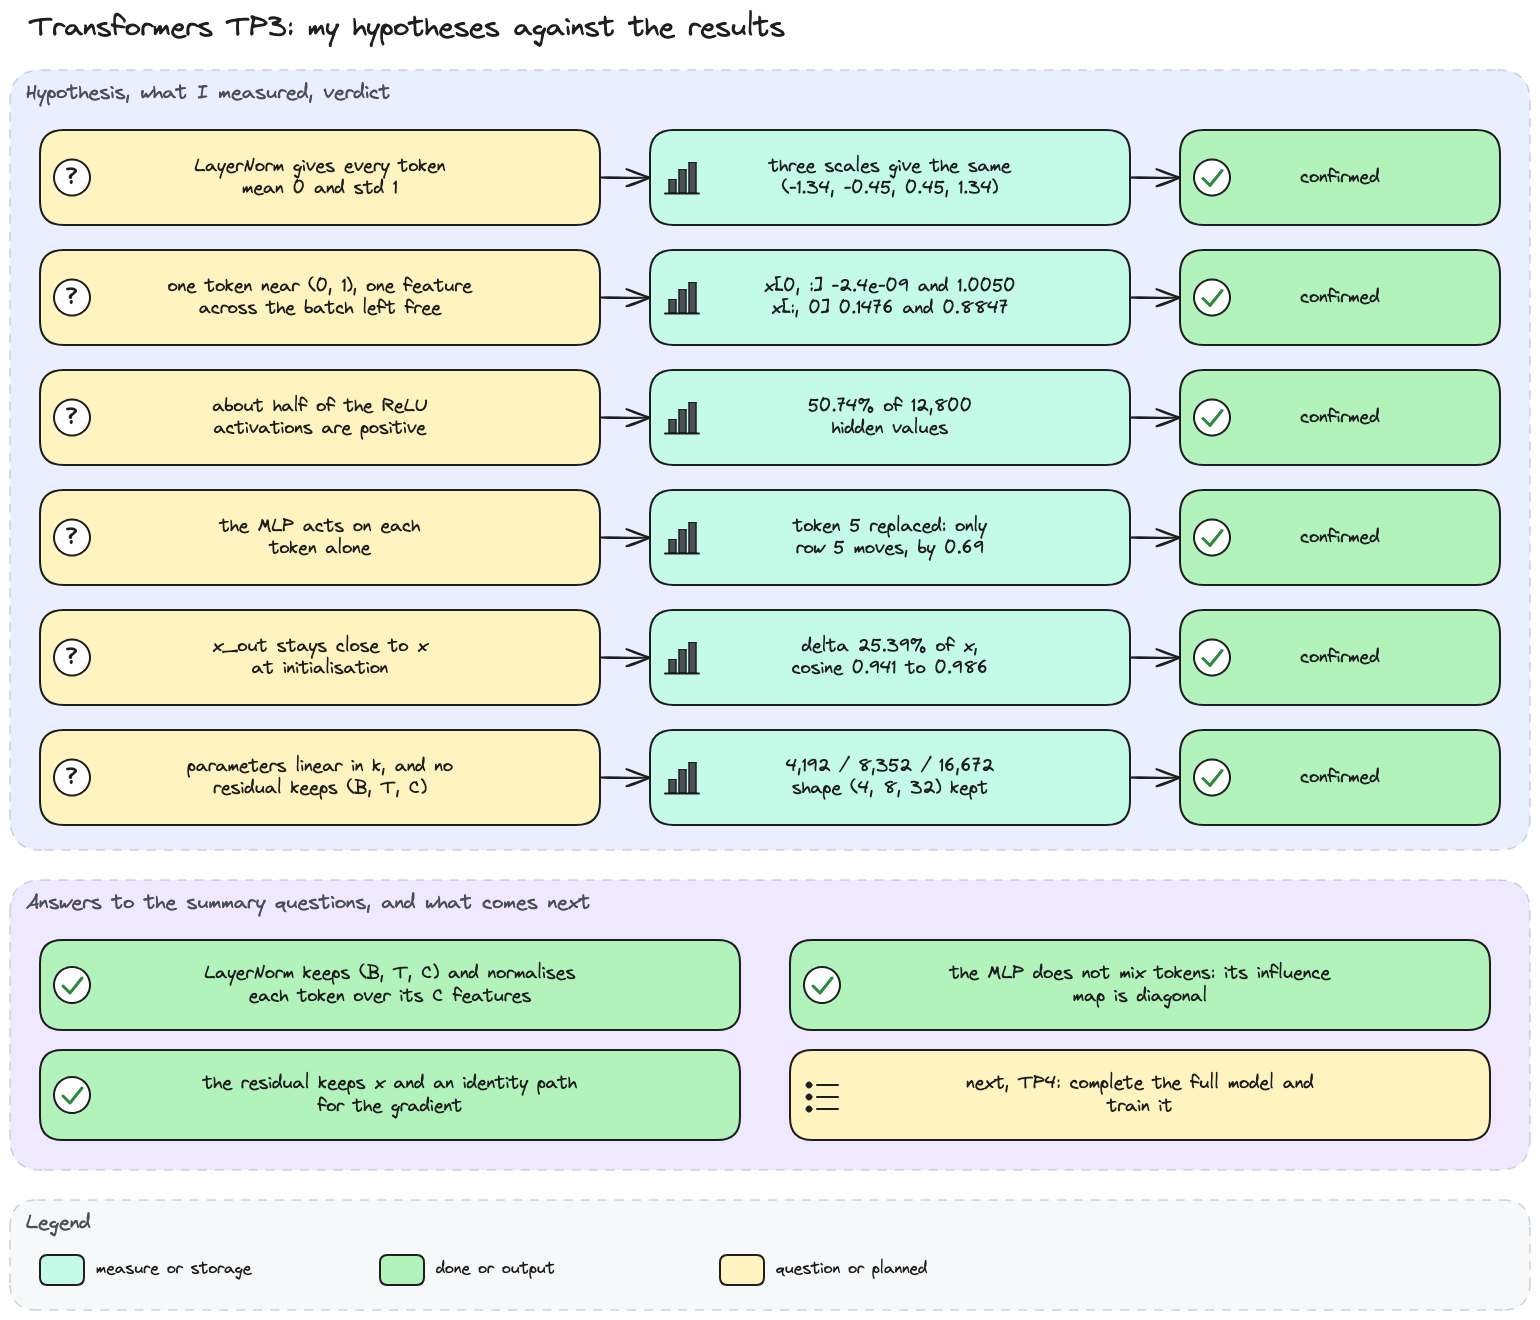

In [42]:
# Summary diagram: my hypotheses, what I measured, my verdicts, and the summary answers.
display(Image(filename='diagrams/transformers/tp3_summary.png', width=900))

In [43]:
# Which dimension does each piece keep? Input and output shapes on two sizes of tokens.
torch.manual_seed(RANDOM_STATE)
for shape in ((4, 8, 32), (32, 100)):
    size = shape[-1]
    tokens_in = torch.randn(shape)
    pieces = {'my LayerNorm1d': LayerNorm1d(size), 'nn.LayerNorm': nn.LayerNorm(size),
              'FeedForward': FeedForward(size)}
    pieces['block'] = lambda v: v + pieces['FeedForward'](pieces['nn.LayerNorm'](v))
    print(f'input {shape}, statistics of LayerNorm over the last dimension, of size {size}')
    for name, piece in pieces.items():
        print(f'    {name}: output {tuple(piece(tokens_in).shape)}')

input (4, 8, 32), statistics of LayerNorm over the last dimension, of size 32
    my LayerNorm1d: output (4, 8, 32)
    nn.LayerNorm: output (4, 8, 32)
    FeedForward: output (4, 8, 32)
    block: output (4, 8, 32)
input (32, 100), statistics of LayerNorm over the last dimension, of size 100
    my LayerNorm1d: output (32, 100)
    nn.LayerNorm: output (32, 100)
    FeedForward: output (32, 100)
    block: output (32, 100)


Every piece returns the shape it receives, (4, 8, 32) and (32, 100). LayerNorm takes its statistics over the last dimension, of size 32 or 100, and leaves the others untouched. So LayerNorm keeps the dimension C and normalises each token along it, while B and T only index separate tokens.

LayerNorm: largest influence on another token 0.00, from a later token 0.00
MLP: largest influence on another token 0.00, from a later token 0.00
block: largest influence on another token 0.00, from a later token 0.00
causal average of TP2: largest influence on another token 2.83, from a later token 0.00


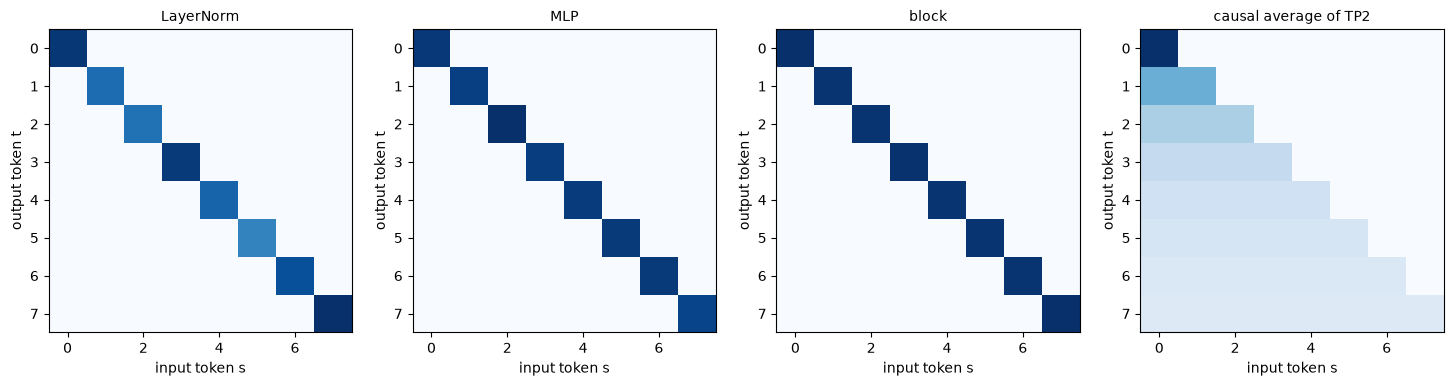

In [44]:
# Does any piece mix positions? How much input token s moves output token t, in sequence 0.
causal_average = torch.tril(torch.ones(T, T))
causal_average = causal_average / causal_average.sum(1, keepdim=True)
pieces = {'LayerNorm': layer_norm, 'MLP': ffwd, 'block': lambda v: v + ffwd(layer_norm(v)),
          'causal average of TP2': lambda v: causal_average @ v}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, piece) in zip(axes, pieces.items()):
    jacobian = torch.autograd.functional.jacobian(piece, x[0])  # (T, C, T, C)
    influence = jacobian.norm(dim=(1, 3))  # (T, T): output token t, input token s
    others = influence - torch.diag(torch.diag(influence))
    print(f'{name}: largest influence on another token {others.max():.2f}, '
          f'from a later token {influence.triu(1).max():.2f}')
    ax.imshow(influence, cmap='Blues')
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('input token s')
    ax.set_ylabel('output token t')
plt.show()

For LayerNorm, the MLP and the whole block, the largest influence of one token on another is 0.00, so each map is a pure diagonal. The causal average of TP2 reaches 2.83 off the diagonal, in its lower triangle, and 0.00 from a later token.

So the pieces of TP3 never mix positions, and the mixing of a Transformer block comes from attention alone. Both kinds keep the rule of TP2, since nothing comes from a later token.

LayerNorm(32): 64 parameters, 0.64% of 9,952
MLP 4C: 8,352 parameters, 83.92% of 9,952
TP2 head, d_h = 16: 1,536 parameters, 15.43% of 9,952


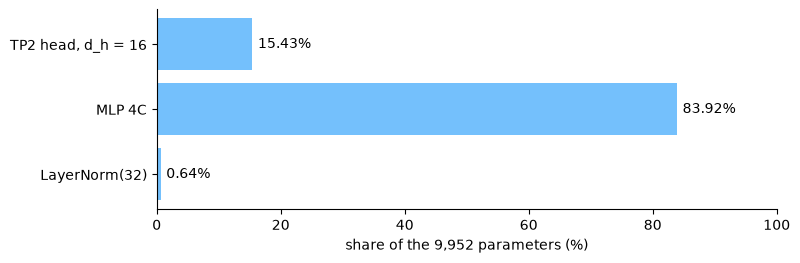

In [45]:
# Where do the weights of a block sit? Parameters per piece for C = 32, with the head of TP2.
budget = {name: counts[name] for name in ('LayerNorm(32)', 'MLP 4C', 'TP2 head, d_h = 16')}
total = sum(budget.values())
for name, count in budget.items():
    print(f'{name}: {count:,} parameters, {100 * count / total:.2f}% of {total:,}')

fig, ax = plt.subplots(figsize=(8, 2.6))
bars = ax.barh(list(budget), [100 * count / total for count in budget.values()], color='#74c0fc')
ax.bar_label(bars, labels=[f'{100 * count / total:.2f}%' for count in budget.values()], padding=4)
ax.set_xlim(0, 100)
ax.set_xlabel(f'share of the {total:,} parameters (%)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

In a block made of LayerNorm, an MLP at 4C and my TP2 head, the MLP holds 83.92% of the 9,952 parameters. The head holds 15.43% and LayerNorm only 0.64%. So most of the weights of a block sit in the part that works on each token alone, and mixing positions costs far fewer weights.

> *My conclusion:*
>
> I built the two operations that act on each token alone and checked them against my six hypotheses. All six hold.
>
> - LayerNorm gives every token a mean of 0 and a std of 1. Three scales of (2, 4, 6, 8) all gave (−1.34, −0.45, 0.45, 1.34).
> - On a batch, token 0 sits at a mean of −2.4e-09 and a std of 1.0050, while feature 0 stays free at 0.1476 and 0.8847.
> - 50.74% of the ReLU activations are positive before training.
> - The MLP acts on each token alone, since replacing token 5 moved only row 5.
> - In the pre-norm block, `delta` is 25.39% of `x` on average, so `x_out` stays close to `x`.
> - The parameters grow by 2,080 per unit of k, and removing the residual keeps the shape (4, 8, 32).
>
> LayerNorm fixes the scale that each sub-layer sees, the MLP transforms each token, and the residual keeps the input with a direct path for the gradient. None of them mixes positions, which leaves that job to attention.
>
> My answers to the three summary questions of TP3:
>
> 1. LayerNorm keeps the shape (B, T, C) and the dimension C, over which it normalises each token on its own.
> 2. The MLP does not mix tokens. Its influence map is diagonal, with 0.00 between different tokens.
> 3. The residual connection keeps the input in the output and gives the gradient an identity path. Without it the cosine to `x` falls to 0.023, and over 32 blocks the gradient stays at or below 0.30 times ||g||.
>
> These checks use one seed, untrained blocks and C = 32 or 100. TP4 assembles the full model, where these blocks will be trained.